# Single-run Kaggle evaluation: five base models, all three datasets

Five original checkpoints, three anatomical datasets, two question types, and two
test-input conditions: **60 evaluations (30 closed + 30 open)**. No Arup330 adapters
are loaded and no training occurs. Here With/Without denotes **test-time CoT**,
not the training condition used in notebooks 2 and 3.

Kaggle: enable Internet and a GPU; attach the CT test images and CoT CSVs for
BrainFace, Neck, and Abdomen. Add an enabled `HF_TOKEN` secret with access to
`google/medgemma-4b-it` (accept its terms on Hugging Face first).
Use a fresh Kaggle GPU session and choose Run All. All datasets, models and
conditions are enabled by default. The last cell displays two combined 30-row
tables, six dataset-specific tables, With/Without differences, category tables
and closed-question confusion matrices (PNG/PDF/CSV). Category fields default to
`content_type` and `base_type`; categories are read from the CSV, not inferred. Attach extracted test datasets or test
CoT ZIPs; recognized test ZIPs are discovered automatically when needed.

The original first-experiment prompts are retained, including the empty reasoning
field for Without. Both conditions use exactly the same eligible test rows.
Blank CoT rows are excluded from BOTH conditions and reported. Closed answers
other than Yes/No are excluded and reported; invalid model outputs count as wrong.
Open metrics match the final fine-tuned open notebook: corpus BLEU-4 (method1),
unstemmed ROUGE F1, and unrescaled roberta-large BERTScore. They therefore differ
from the older first-experiment mean sentence BLEU and stemmed ROUGE settings.

Existing test CoT is read as supplied. This notebook never generates CoT or inserts
reference answers into prompts. If the supplied CoT was generated using reference
answers, that remains a limitation of the data and must be disclosed in reporting.

One model is loaded at a time in 4-bit; inference uses batch size 1. All model
weights must still be downloaded, so allow sufficient temporary disk space.
A single Kaggle session is not guaranteed to finish all runs within its resource
limits. Row checkpoints allow continuation. No failed model is silently skipped.

Execution order: all 30 closed evaluations first, then all 30 open evaluations.
Models and processors are released between model loads and CUDA caches are cleared
on each available device. A closed-stage summary is saved before open inference.
With cache deletion enabled, the open stage downloads the checkpoint again; this
keeps disk use bounded to one model cache. Disabling deletion requires space for
all five checkpoints. Memory cleanup does not guarantee that every model fits
the selected GPU or that all evaluations finish within Kaggle's session limits.
Dataset filenames: Abdomen uses closed_with_CoT.csv / Open_with_CoT.csv;
BrainFace and Neck use closed.csv / open.csv containing CoT.

Closed reporting is now a separate stage before any open inference: overall and dataset
summaries, category tables, With/Without differences, all confusion matrices, a text
report and closed_evaluation_report.zip are completed first. The final combined
report remains available after open evaluation.


In [1]:
%pip install -q "transformers==4.57.3" "accelerate>=1.2,<2" "bitsandbytes>=0.46,<0.49" "huggingface_hub>=0.34,<1" pandas pillow scikit-learn nltk rouge-score bert-score sentencepiece protobuf matplotlib jinja2


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, gc, json, hashlib, shutil, zipfile, unicodedata
from pathlib import Path
from functools import lru_cache
from importlib.metadata import version
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from huggingface_hub import HfApi, hf_hub_download
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from rouge_score import rouge_scorer
from bert_score import BERTScorer

os.environ.pop('HF_HUB_ENABLE_HF_TRANSFER', None)
HF_TOKEN = os.environ.get('HF_TOKEN')
try:
    from kaggle_secrets import UserSecretsClient
    for secret_name in ('HF_TOKEN', 'HF_Token'):
        try:
            HF_TOKEN = UserSecretsClient().get_secret(secret_name) or HF_TOKEN
            if HF_TOKEN:
                break
        except Exception:
            pass
except ImportError:
    pass
print('HF token available:', bool(HF_TOKEN))  # Never print the token.


I0000 00:00:1795583409.057766      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


HF token available: True


In [3]:
# 1. Configuration
DATA_ROOT = '/kaggle/input/datasets/arups330/slackdataset/SLAKE_split_en_realimages'
DATASETS = ['BrainFace', 'Neck', 'Abdomen']
TASKS = ['closed', 'open']
CONDITIONS = ['With', 'Without']
MODELS = {
    'Lingshu-7B': 'lingshu-medical-mllm/Lingshu-7B',
    'MedGemma-4B': 'google/medgemma-4b-it',
    'Qwen2.5-VL-7B': 'Qwen/Qwen2.5-VL-7B-Instruct',
    'Qwen3-VL-8B': 'Qwen/Qwen3-VL-8B-Instruct',
    'Llama-11B': 'unsloth/Llama-3.2-11B-Vision-Instruct',
}
RUN_MODELS = list(MODELS)
RUN_DATASETS = list(DATASETS)
RUN_TASKS = list(TASKS)
MAX_ROWS_PER_DATASET = None  # Optional smoke test; None evaluates all eligible rows.
MAX_IMAGE_SIDE = None  # Preserve original images by default.
MAX_NEW_TOKENS = {'closed': 8, 'open': 32}
CATEGORY_COLUMNS = ['content_type', 'base_type']
FIGURES_DIR = Path('/kaggle/working/base_model_eval_results/confusion_matrices')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

BERTSCORE_MODEL = 'roberta-large'
BERTSCORE_BATCH_SIZE = 8

# Discovery searches attached Kaggle datasets for *_with_CoT.csv under test/.
# Set exact paths here if discovery finds multiple copies or nonstandard names.
CSV_OVERRIDES = {}  # e.g. {('BrainFace', 'closed'): '/kaggle/input/.../closed_with_CoT.csv'}
# If an image is not beside its CSV, specify the corresponding CT/test image folder.
IMAGE_DIR_OVERRIDES = {}  # e.g. {('BrainFace', 'open'): '/kaggle/input/.../CT/test'}
# Optional attached ZIPs; their contents are extracted below, without modifying input data.
AUTO_DISCOVER_TEST_ZIPS = True
TEST_ZIPS = {}  # e.g. {'BrainFace': '/kaggle/input/.../BrainFace_Test_with_CoT.zip'}
EXTRA_SEARCH_ROOTS = []
RESUME_RAW_DIRS = []  # Previous Kaggle output's raw_base_models folder.
RESULTS_DIR = Path('/kaggle/working/base_model_eval_results')
RAW_DIR = RESULTS_DIR / 'raw_base_models'
EXTRACT_DIR = RESULTS_DIR / 'extracted_test'
CACHE_ROOT = Path('/kaggle/working/base_eval_weight_cache')
DELETE_MODEL_CACHE_AFTER_SUCCESS = True  # Only this notebook's dedicated per-model cache.
for directory in (RESULTS_DIR, RAW_DIR, CACHE_ROOT):
    directory.mkdir(parents=True, exist_ok=True)
assert set(RUN_MODELS) <= set(MODELS)
assert set(RUN_DATASETS) <= set(DATASETS) and set(RUN_TASKS) <= set(TASKS)
assert MAX_ROWS_PER_DATASET is None or (type(MAX_ROWS_PER_DATASET) is int and MAX_ROWS_PER_DATASET > 0)
for name, repo in MODELS.items():
    print(f'{name}: {repo}')


# These are original pretrained/instruction checkpoints, not your study's adapters.
assert all(not repo.lower().startswith('arup330/') for repo in MODELS.values())
EXPECTED_EVALUATIONS = len(DATASETS) * len(TASKS) * len(MODELS) * len(CONDITIONS)
RUN_PLAN = pd.DataFrame([
    {'Dataset': d, 'Question type': t, 'Model': m, 'Checkpoint': repo,
     'Test CoT': c, 'Input': 'image + question + CoT' if c == 'With' else 'image + question'}
    for m, repo in MODELS.items() for d in DATASETS for t in TASKS for c in CONDITIONS
])
print(f'\nRun All: {len(MODELS)} base checkpoints, {EXPECTED_EVALUATIONS} evaluations.')
print('Test CSVs must contain question, answer, CoT and image_file/img_name/image.')
RUN_PLAN.to_csv(RESULTS_DIR / 'evaluation_plan.csv', index=False)
display(RUN_PLAN)


Lingshu-7B: lingshu-medical-mllm/Lingshu-7B
MedGemma-4B: google/medgemma-4b-it
Qwen2.5-VL-7B: Qwen/Qwen2.5-VL-7B-Instruct
Qwen3-VL-8B: Qwen/Qwen3-VL-8B-Instruct
Llama-11B: unsloth/Llama-3.2-11B-Vision-Instruct

Run All: 5 base checkpoints, 60 evaluations.
Test CSVs must contain question, answer, CoT and image_file/img_name/image.


,Dataset,Question type,Model,Checkpoint,Test CoT,Input
0,BrainFace,closed,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,With,image + question + CoT
1,BrainFace,closed,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,Without,image + question
2,BrainFace,open,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,With,image + question + CoT
3,BrainFace,open,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,Without,image + question
4,Neck,closed,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,With,image + question + CoT
5,Neck,closed,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,Without,image + question
6,Neck,open,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,With,image + question + CoT
7,Neck,open,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,Without,image + question
8,Abdomen,closed,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,With,image + question + CoT
9,Abdomen,closed,Lingshu-7B,lingshu-medical-mllm/Lingshu-7B,Without,image + question


In [4]:
# 2. Read CT test rows only; preflight every image before downloading model weights.
def norm(text):
    return ' '.join(unicodedata.normalize('NFKC', str(text)).lower().split())

def binary(text):
    value = norm(text).strip(' .,!?:;\"\'')
    return value if value in ('yes', 'no') else '__invalid__'

def image_path(csv_path, image_name, dataset, task):
    name = str(image_name).replace('\\', '/')
    roots = [Path(csv_path).parent]
    if (dataset, task) in IMAGE_DIR_OVERRIDES:
        roots.insert(0, Path(IMAGE_DIR_OVERRIDES[dataset, task]))
    folder_aliases = ['BrainFace', 'Brain_Face', 'Brainface'] if dataset == 'BrainFace' else [dataset]
    for alias in folder_aliases:
        roots.extend([Path(DATA_ROOT)/alias/'CT'/'test', Path(DATA_ROOT)/alias/'CT'/'Test'])
    for root in roots:
        for candidate in (root/name, root/Path(name).name, root/name.replace('/', '_')):
            if candidate.is_file():
                return str(candidate.resolve())
    raise FileNotFoundError(f'{dataset}/{task}: image {name!r} not found beside {csv_path}. Set IMAGE_DIR_OVERRIDES.')


def collect_csvs(search_roots):
    return sorted({p.resolve() for root in search_roots if root.exists()
                   for p in root.rglob('*') if p.is_file() and p.suffix.lower() == '.csv'})

def matching_csvs(dataset, task, paths):
    # Exact filenames from your uploaded dataset structure (case-insensitive).
    expected = f"{task}_with_cot.csv" if dataset == "Abdomen" else f"{task}.csv"
    matches, preferred = [], []
    region = re.sub(r"[^a-z]", "", dataset.lower())
    for path in paths:
        path = Path(path)
        if path.name.lower() != expected:
            continue
        parts = [part.lower() for part in path.parts]
        compact_parts = [re.sub(r"[^a-z]", "", part) for part in parts]
        if not any(region in part for part in compact_parts):
            continue
        if "test" not in parts:
            continue
        if any(part in ("train", "validation", "val", "mri", "xray", "ultrasound")
               for part in parts):
            continue
        columns = pd.read_csv(path, nrows=0).columns
        if "cot" not in {str(col).strip().lower() for col in columns}:
            continue
        matches.append(path)
        # Prefer the dedicated test-CoT folders over copies in the general dataset.
        if any(region in part and "test" in part and "cot" in part
               for part in compact_parts[:-1]):
            preferred.append(path)
    return preferred or matches

roots = [Path(DATA_ROOT), Path('/kaggle/input'), EXTRACT_DIR, *map(Path, EXTRA_SEARCH_ROOTS)]
candidates = collect_csvs(roots)
archives = dict(TEST_ZIPS)
if AUTO_DISCOVER_TEST_ZIPS:
    zip_paths = sorted({p.resolve() for root in roots if root.exists()
                        for p in root.rglob('*') if p.is_file() and p.suffix.lower() == '.zip'})
    for dataset in DATASETS:
        if dataset in archives:
            continue
        needed = [t for t in TASKS if (dataset, t) not in CSV_OVERRIDES
                  and not matching_csvs(dataset, t, candidates)]
        if not needed:
            continue
        matches = []
        for archive in zip_paths:
            name = re.sub('[^a-z]', '', archive.stem.lower())
            if dataset.lower() in name and 'test' in name and 'cot' in name:
                matches.append(archive)
        if len(matches) > 1:
            raise ValueError(f'{dataset}: multiple test ZIPs found: {matches}. Select one in TEST_ZIPS.')
        if matches:
            archives[dataset] = matches[0]

archive_roots = {}
for dataset, archive in archives.items():
    assert dataset in DATASETS
    target = (EXTRACT_DIR / dataset).resolve()
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            if not (target/member.filename).resolve().is_relative_to(target):
                raise ValueError(f'Unsafe ZIP member: {member.filename}')
        z.extractall(target)
    archive_roots[dataset] = target
    print(f'[TEST ZIP] {dataset}: {archive}')

candidates = collect_csvs(roots)

def discover(dataset, task):
    if (dataset, task) in CSV_OVERRIDES:
        return Path(CSV_OVERRIDES[dataset, task])
    paths = candidates
    # An explicitly selected/extracted archive takes priority over duplicate copies.
    if dataset in archive_roots:
        paths = [p for p in paths if p.is_relative_to(archive_roots[dataset])]
    matches = matching_csvs(dataset, task, paths)
    if len(matches) != 1:
        raise ValueError(f'{dataset}/{task}: expected ONE CoT test CSV, found {len(matches)}: '
                         f'{list(map(str, matches))}. Attach test CoT data or set CSV_OVERRIDES.')
    return matches[0]

TEST, DATA_AUDIT = {}, []
for dataset in DATASETS:
    for task in TASKS:
        path = discover(dataset, task)
        frame = pd.read_csv(path, keep_default_na=False)
        columns = {c.strip().lower(): c for c in frame.columns}
        for needed in ('question', 'answer', 'cot'):
            if needed not in columns:
                raise ValueError(f'{path}: missing {needed} column')
        image_col = next((columns[x] for x in ('image_file', 'img_name', 'image') if x in columns), None)
        if image_col is None:
            raise ValueError(f'{path}: no image_file/img_name/image column')
        original = len(frame)
        print(f'{dataset}/{task}: category fields available: '
              f'{[key for key in CATEGORY_COLUMNS if key in columns]}')
        if 'modality' in columns and not frame[columns['modality']].map(norm).eq('ct').all():
            raise ValueError(f'{path}: contains non-CT rows; supply the CT test CSV')
        cot_ok = frame[columns['cot']].astype(str).str.strip().ne('')
        nonbinary = frame[columns['answer']].map(binary).eq('__invalid__') if task == 'closed' else pd.Series(False, index=frame.index)
        eligible = frame.loc[cot_ok & ~nonbinary]
        if MAX_ROWS_PER_DATASET is not None:
            eligible = eligible.head(MAX_ROWS_PER_DATASET)
        rows = []
        for idx, row in eligible.iterrows():
            if not str(row[columns['question']]).strip() or not str(row[columns['answer']]).strip():
                raise ValueError(f'{path} row {idx}: empty question or answer')
            img = image_path(path, row[image_col], dataset, task)
            with Image.open(img) as image:
                image.verify()
            rows.append({'source_row': int(idx), 'question': str(row[columns['question']]),
                         'cot': str(row[columns['cot']]), 'gold': norm(row[columns['answer']]) if task == 'open' else binary(row[columns['answer']]),
                         'img_path': img,
                         'categories': {key: str(row[columns[key]]).strip() or 'Unknown'
                                        for key in CATEGORY_COLUMNS if key in columns}})
        if not rows:
            raise ValueError(f'{dataset}/{task}: no eligible rows')
        TEST[dataset, task] = rows
        DATA_AUDIT.append({'Dataset': dataset, 'Task': task, 'CSV': str(path), 'Original': original,
                           'Blank CoT': int((~cot_ok).sum()), 'Nonbinary': int(nonbinary.sum()),
                           'Evaluated per condition': len(rows)})
audit = pd.DataFrame(DATA_AUDIT)
display(audit)
audit.to_csv(RESULTS_DIR/'dataset_audit.csv', index=False)


BrainFace/closed: category fields available: ['content_type', 'base_type']
BrainFace/open: category fields available: ['content_type', 'base_type']
Neck/closed: category fields available: ['content_type', 'base_type']
Neck/open: category fields available: ['content_type', 'base_type']
Abdomen/closed: category fields available: ['content_type', 'base_type']
Abdomen/open: category fields available: ['content_type', 'base_type']


,Dataset,Task,CSV,Original,Blank CoT,Nonbinary,Evaluated per condition
0,BrainFace,closed,/kaggle/input/datasets/arups330/slackdataset/B...,12,0,0,12
1,BrainFace,open,/kaggle/input/datasets/arups330/slackdataset/B...,17,0,0,17
2,Neck,closed,/kaggle/input/datasets/arups330/slackdataset/N...,16,0,0,16
3,Neck,open,/kaggle/input/datasets/arups330/slackdataset/N...,19,0,0,19
4,Abdomen,closed,/kaggle/input/datasets/arups330/slackdataset/A...,127,0,19,108
5,Abdomen,open,/kaggle/input/datasets/arups330/slackdataset/A...,153,0,0,153


In [5]:
# 3. Original first-experiment prompts (answer the question, not a reasoning-validity label).
def closed_prompt(question, cot):
    return f"""
              Context:
                     You are a board-certified radiologist and Medical Visual Question Answering (MedVQA) expert with experience interpreting X-ray, CT, MRI, Ultrasound, and other medical images.

              Objective:
                      Answer the user's question by verifying whether it is supported by the visual evidence in the medical image.

              Inputs:
              Question: {question}

              You have to think step by step.

              Instructions:
              1. Examine the medical image carefully.
              2. Independently determine the relevant visual findings before considering the CoT.
              3. Compare your own observations with the provided CoT.
              4. If the CoT is inconsistent with the image, disregard it.
              5. Answer the question using the following evidence priority:
                1. Medical image (highest priority)
                2. User question
                3. CoT (only if verified by the image)
              6. Never fabricate findings or rely on assumptions.
              7. If the image does not provide sufficient evidence to support a "Yes" answer, return "No."

              Output Requirements:
              - Output exactly one word.
              - Do not provide explanations, punctuation, or additional text.

              Valid outputs:
              Yes
              No
             Step of thinking: {cot}
           """

def open_prompt(question, cot):
    return f"""
              Context:
                     You are a board-certified radiologist and Medical Visual Question Answering (MedVQA) expert with experience interpreting X-ray, CT, MRI, Ultrasound, and other medical images.

              Objective:
                      Answer the user's question by verifying whether it is supported by the visual evidence in the medical image.

              Inputs:
              Question: {question}

              You have to think step by step.

              Instructions:
              1. Examine the medical image carefully.
              2. Independently determine the relevant visual findings before considering the CoT.
              3. Compare your own observations with the provided CoT.
              4. If the CoT is inconsistent with the image, disregard it.
              5. Answer the question using the following evidence priority:
                1. Medical image (highest priority)
                2. User question
                3. CoT (only if verified by the image)
              6. Never fabricate findings or rely on assumptions.

              Output Requirements:
              - Return ONLY the final answer in 1 to 4 words. Do not explain.
              Reasoning Reference:
              {cot}

              Use it only if it agrees with the image.
            """


def make_prompt(row, task, condition):
    cot = row['cot'] if condition == 'With' else ''
    return (closed_prompt if task == 'closed' else open_prompt)(row['question'], cot)


In [7]:
# 4. Check access before inference, and pin each run to its resolved Hub commit.
if not torch.cuda.is_available():
    raise RuntimeError('Enable a Kaggle GPU accelerator before continuing.')
api = HfApi(token=HF_TOKEN)
REVISIONS, access_errors = {}, []
MODEL_MANIFEST = []
for name, repo in MODELS.items():
    try:
        info = api.model_info(repo)
        files = {f.rfilename for f in (info.siblings or [])}
        if 'adapter_config.json' in files:
            raise ValueError('An adapter repository was configured. Use the original base checkpoint.')
        REVISIONS[name] = info.sha
        MODEL_MANIFEST.append({'Model': name, 'Checkpoint': repo, 'Revision': info.sha})
        # A public model_info response alone does not prove gated file access.
        hf_hub_download(repo, 'config.json', revision=info.sha, token=HF_TOKEN)
        print(f'[ACCESS OK] {name}: {repo} @ {info.sha[:12]}')
    except Exception as exc:
        access_errors.append(f'{name}: {type(exc).__name__}: {exc}')
if access_errors:
    raise RuntimeError('Fix access before evaluation (MedGemma requires accepted terms and HF_TOKEN):\n'
                       + '\n'.join(access_errors))
pd.DataFrame(MODEL_MANIFEST).to_csv(RESULTS_DIR/'model_manifest.csv', index=False)
COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('GPU:', torch.cuda.get_device_name(0), '| dtype:', COMPUTE_DTYPE)

def load_model(name):
    repo = MODELS[name]
    cache = CACHE_ROOT/name
    processor = AutoProcessor.from_pretrained(repo, revision=REVISIONS[name], token=HF_TOKEN, cache_dir=cache)
    model = AutoModelForImageTextToText.from_pretrained(
        repo, revision=REVISIONS[name], token=HF_TOKEN, cache_dir=cache,
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE),
        torch_dtype=COMPUTE_DTYPE, device_map='auto', attn_implementation='sdpa',
    ).eval()
    return model, processor

@torch.inference_mode()
def generate_answer(model, processor, row, task, condition):
    with Image.open(row['img_path']) as source:
        image = source.convert('RGB')
    try:
        if MAX_IMAGE_SIDE:
            image.thumbnail((MAX_IMAGE_SIDE, MAX_IMAGE_SIDE))
        messages = [{'role': 'user', 'content': [
            {'type': 'image', 'image': image},
            {'type': 'text', 'text': make_prompt(row, task, condition)},
        ]}]
        inputs = processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True,
            return_dict=True, return_tensors='pt').to(model.device)
        generated = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS[task],
                                   do_sample=False, use_cache=True)
        return processor.decode(generated[0, inputs['input_ids'].shape[1]:], skip_special_tokens=True).strip()
    finally:
        image.close()


[ACCESS OK] Lingshu-7B: lingshu-medical-mllm/Lingshu-7B @ b98aecd41dfd


config.json: 0.00B [00:00, ?B/s]

[ACCESS OK] MedGemma-4B: google/medgemma-4b-it @ 290cda5eeccb
[ACCESS OK] Qwen2.5-VL-7B: Qwen/Qwen2.5-VL-7B-Instruct @ cc594898137f
[ACCESS OK] Qwen3-VL-8B: Qwen/Qwen3-VL-8B-Instruct @ 0c351dd01ed8
[ACCESS OK] Llama-11B: unsloth/Llama-3.2-11B-Vision-Instruct @ 677b0c1b7008
GPU: Tesla T4 | dtype: torch.bfloat16


Overall progress: 0/60 complete evaluations

STARTING CLOSED EVALUATION -- ALL SELECTED MODELS AND DATASETS
GPU 0: allocated=0.00 GiB, reserved=0.00 GiB
GPU 1: allocated=0.00 GiB, reserved=0.00 GiB

--- Loading lingshu-medical-mllm/Lingshu-7B | CLOSED ---


preprocessor_config.json:   0%|          | 0.00/575 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/575 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (17 outputs left out)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


    [1/12] gold='yes' pred='yes' raw='Yes'


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/12] gold='no' pred='no' raw='No.'
    [3/12] gold='yes' pred='no' raw='No'
    [4/12] gold='no' pred='no' raw='No'
    [5/12] gold='no' pred='no' raw='No.'
    [6/12] gold='no' pred='no' raw='No.'
    [7/12] gold='yes' pred='yes' raw='Yes'
    [8/12] gold='no' pred='no' raw='No.'
    [9/12] gold='yes' pred='yes' raw='Yes'
    [10/12] gold='yes' pred='yes' raw='Yes'
    [11/12] gold='no' pred='no' raw='No.'
    [12/12] gold='no' pred='no' raw='No.'
Classification report -- Lingshu-7B (With CoT, BrainFace):
              precision    recall  f1-score   support

          no     0.8750    1.0000    0.9333         7
         yes     1.0000    0.8000    0.8889         5

    accuracy                         0.9167        12
   macro avg     0.9375    0.9000    0.9111        12
weighted avg     0.9271    0.9167    0.9148        12

Accuracy: 91.67% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Yes
No    7    0
Yes   1    4


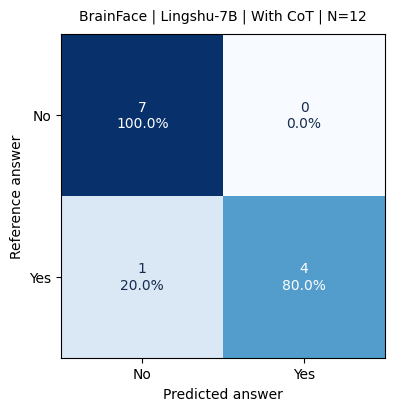

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace Lingshu-7B With   content_type       KG  4        100.00              50.00           50.00       50.00                100.00             100.00         100.00       0.0/0.0/0.0 100.0/100.0/100.0        0
BrainFace Lingshu-7B With   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace Lingshu-7B With   content_type    Organ  5         80.00              83.33           83.33       80.00                 86.67              80.00          80.00   100.0/66.7/80.0   66.7/100.0/80.0        0
BrainFace Lingshu-7B With   content_type    Plane  1        100.00  

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/12] gold='no' pred='no' raw='No.'
    [3/12] gold='yes' pred='yes' raw='Yes.'
    [4/12] gold='no' pred='no' raw='No.'
    [5/12] gold='no' pred='no' raw='No.'
    [6/12] gold='no' pred='no' raw='No.'
    [7/12] gold='yes' pred='yes' raw='Yes.'
    [8/12] gold='no' pred='no' raw='No.'
    [9/12] gold='yes' pred='yes' raw='Yes.'
    [10/12] gold='yes' pred='yes' raw='Yes.'
    [11/12] gold='no' pred='no' raw='No.'
    [12/12] gold='no' pred='no' raw='No.'
Classification report -- Lingshu-7B (Without CoT, BrainFace):
              precision    recall  f1-score   support

          no     1.0000    1.0000    1.0000         7
         yes     1.0000    1.0000    1.0000         5

    accuracy                         1.0000        12
   macro avg     1.0000    1.0000    1.0000        12
weighted avg     1.0000    1.0000    1.0000        12

Accuracy: 100.00% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Yes
No    7    0
Yes   0    5


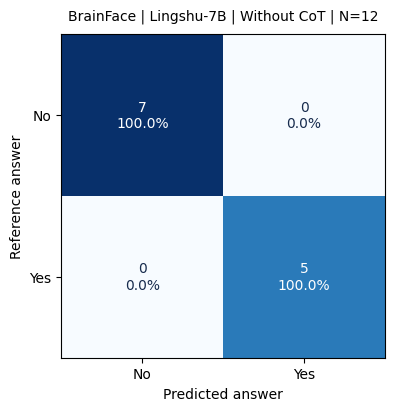

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace Lingshu-7B Without   content_type       KG  4        100.00              50.00           50.00       50.00                100.00             100.00         100.00       0.0/0.0/0.0 100.0/100.0/100.0        0
BrainFace Lingshu-7B Without   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace Lingshu-7B Without   content_type    Organ  5        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
BrainFace Lingshu-7B Without   content_type    Plane  1 

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/16] gold='no' pred='no' raw='No.'
    [3/16] gold='no' pred='no' raw='No.'
    [4/16] gold='yes' pred='no' raw='No.'
    [5/16] gold='yes' pred='yes' raw='Yes'
    [6/16] gold='yes' pred='yes' raw='Yes'
    [7/16] gold='no' pred='no' raw='No.'
    [8/16] gold='no' pred='no' raw='No.'
    [9/16] gold='yes' pred='no' raw='No.'
    [10/16] gold='no' pred='no' raw='No.'
    [11/16] gold='no' pred='no' raw='No.'
    [12/16] gold='yes' pred='yes' raw='Yes'
    [13/16] gold='yes' pred='yes' raw='Yes'
    [14/16] gold='no' pred='no' raw='No.'
    [15/16] gold='no' pred='no' raw='No.'
    [16/16] gold='yes' pred='yes' raw='Yes'
Classification report -- Lingshu-7B (With CoT, Neck):
              precision    recall  f1-score   support

          no     0.8182    1.0000    0.9000         9
         yes     1.0000    0.7143    0.8333         7

    accuracy                         0.8750        16
   macro avg     0.9091    0.8571    0.8667        16
weighted avg     0.8977    0.8750    0.8

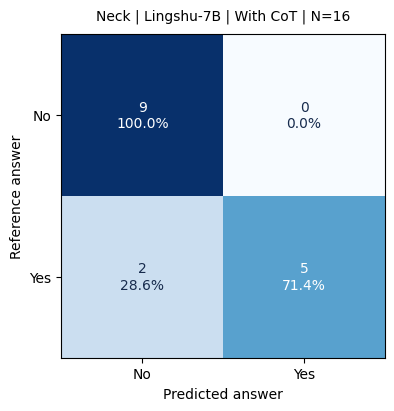

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck Lingshu-7B With   content_type       KG  6         66.67              75.00           75.00       66.67                 83.33              66.67          66.67   100.0/50.0/66.7   50.0/100.0/66.7        0
   Neck Lingshu-7B With   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Lingshu-7B With   content_type    Organ  6        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Lingshu-7B With   content_type    Plane  1        100.00            

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/16] gold='no' pred='yes' raw='Yes.'
    [3/16] gold='no' pred='yes' raw='Yes.'
    [4/16] gold='yes' pred='no' raw='No.'
    [5/16] gold='yes' pred='no' raw='No.'
    [6/16] gold='yes' pred='yes' raw='Yes.'
    [7/16] gold='no' pred='no' raw='No.'
    [8/16] gold='no' pred='no' raw='No.'
    [9/16] gold='yes' pred='yes' raw='Yes'
    [10/16] gold='no' pred='no' raw='No.'
    [11/16] gold='no' pred='no' raw='No.'
    [12/16] gold='yes' pred='yes' raw='Yes.'
    [13/16] gold='yes' pred='yes' raw='Yes'
    [14/16] gold='no' pred='no' raw='No.'
    [15/16] gold='no' pred='no' raw='No.'
    [16/16] gold='yes' pred='yes' raw='Yes'
Classification report -- Lingshu-7B (Without CoT, Neck):
              precision    recall  f1-score   support

          no     0.7778    0.7778    0.7778         9
         yes     0.7143    0.7143    0.7143         7

    accuracy                         0.7500        16
   macro avg     0.7460    0.7460    0.7460        16
weighted avg     0.7500    0.75

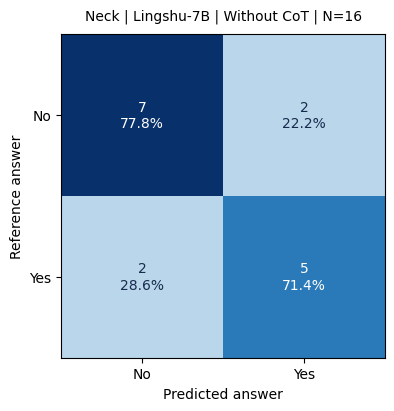

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck Lingshu-7B Without   content_type       KG  6         66.67              75.00           75.00       66.67                 83.33              66.67          66.67   100.0/50.0/66.7   50.0/100.0/66.7        0
   Neck Lingshu-7B Without   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Lingshu-7B Without   content_type    Organ  6         66.67              66.67           80.00       62.50                 88.89              66.67          70.83   33.3/100.0/50.0   100.0/60.0/75.0        0
   Neck Lingshu-7B Without   content_type    Plane  1        100

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No'
    [4/108] gold='yes' pred='yes' raw='Yes'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='no' raw='No.'
    [7/108] gold='no' pred='no' raw='No.'
    [8/108] gold='no' pred='no' raw='No.'
    [9/108] gold='yes' pred='yes' raw='Yes'
    [10/108] gold='yes' pred='yes' raw='Yes'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No.'
    [13/108] gold='no' pred='no' raw='No.'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='yes' raw='Yes'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No.'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No'
    [21/108] gold='no' pred='no' raw='No.'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='no' raw='No.'
    [24/108] gold='yes' pred='yes' raw=

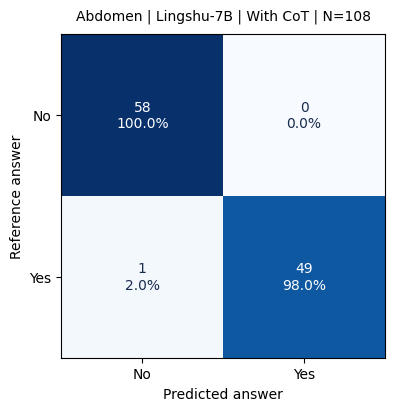

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset Model Name  CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
Abdomen Lingshu-7B With   content_type Abnormality  9        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
Abdomen Lingshu-7B With   content_type          KG 17        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
Abdomen Lingshu-7B With   content_type       Organ 81         98.77              98.91           98.61       98.75                 98.79              98.77          98.76   100.0/97.2/98.6   97.8/100.0/98.9        0
Abdomen Lingshu-7B With   content_type       Plane  1        100

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No.'
    [4/108] gold='yes' pred='yes' raw='Yes'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='no' raw='No.'
    [7/108] gold='no' pred='no' raw='No.'
    [8/108] gold='no' pred='no' raw='No.'
    [9/108] gold='yes' pred='yes' raw='Yes.'
    [10/108] gold='yes' pred='no' raw='No.'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No.'
    [13/108] gold='no' pred='no' raw='No.'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='yes' raw='Yes.'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No.'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No.'
    [21/108] gold='no' pred='no' raw='No.'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='yes' raw='Yes'
    [24/108] gold='yes' pred='yes' 

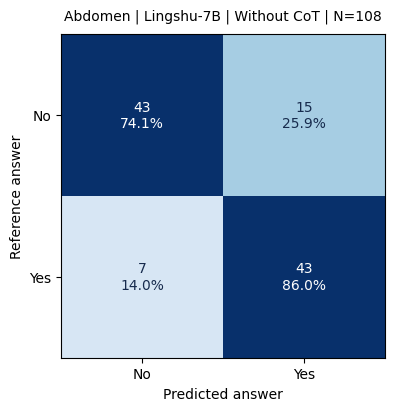

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset Model Name     CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1 No-class P/R/F1  Invalid
Abdomen Lingshu-7B Without   content_type Abnormality  9         66.67              67.50           67.50       66.67                 68.33              66.67          66.67    60.0/75.0/66.7  75.0/60.0/66.7        0
Abdomen Lingshu-7B Without   content_type          KG 17         70.59              73.33           69.44       68.86                 72.94              70.59          69.30    66.7/88.9/76.2  80.0/50.0/61.5        0
Abdomen Lingshu-7B Without   content_type       Organ 81         82.72              82.65           83.06       82.65                 83.22              82.72          82.77    77.5/86.1/81.6  87.8/80.0/83.7        0
Abdomen Lingshu-7B Without   content_type       Plane  1    

config.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

... (11 outputs left out)

generation_config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]


--- MedGemma-4B | CoT: With | BrainFace | closed ---


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [1/12] gold='yes' pred='yes' raw='Yes'
    [2/12] gold='no' pred='no' raw='No'
    [3/12] gold='yes' pred='yes' raw='Yes'
    [4/12] gold='no' pred='no' raw='No'
    [5/12] gold='no' pred='no' raw='No'
    [6/12] gold='no' pred='no' raw='No'
    [7/12] gold='yes' pred='yes' raw='Yes'
    [8/12] gold='no' pred='no' raw='No'
    [9/12] gold='yes' pred='yes' raw='Yes'
    [10/12] gold='yes' pred='yes' raw='Yes'
    [11/12] gold='no' pred='no' raw='No'
    [12/12] gold='no' pred='no' raw='No'
Classification report -- MedGemma-4B (With CoT, BrainFace):
              precision    recall  f1-score   support

          no     1.0000    1.0000    1.0000         7
         yes     1.0000    1.0000    1.0000         5

    accuracy                         1.0000        12
   macro avg     1.0000    1.0000    1.0000        12
weighted avg     1.0000    1.0000    1.0000        12

Accuracy: 100.00% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Y

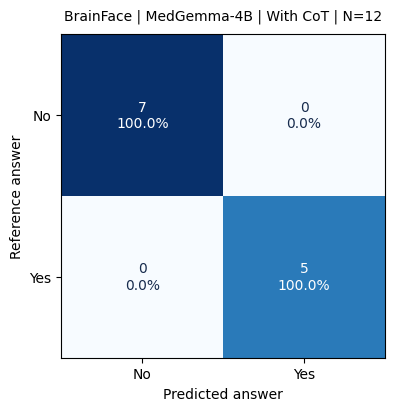

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset  Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace MedGemma-4B With   content_type       KG  4        100.00              50.00           50.00       50.00                100.00             100.00         100.00       0.0/0.0/0.0 100.0/100.0/100.0        0
BrainFace MedGemma-4B With   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace MedGemma-4B With   content_type    Organ  5        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
BrainFace MedGemma-4B With   content_type    Plane  1        100

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [1/12] gold='yes' pred='__invalid__' raw='The image shows a CT scan of the'
    [2/12] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [3/12] gold='yes' pred='__invalid__' raw='The image shows a CT scan of the'
    [4/12] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
    [5/12] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
    [6/12] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
    [7/12] gold='yes' pred='__invalid__' raw='The image shows a CT scan of the'
    [8/12] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
    [9/12] gold='yes' pred='__invalid__' raw='The image shows a CT scan of the'
    [10/12] gold='yes' pred='__invalid__' raw='The image shows a CT scan of the'
    [11/12] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
    [12/12] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
Classification report -- MedGemma-4B (

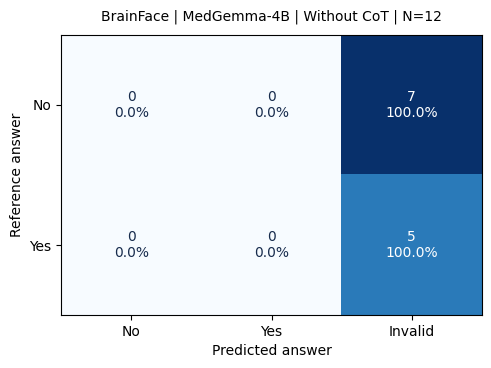

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset  Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted) Yes-class P/R/F1 No-class P/R/F1  Invalid
BrainFace MedGemma-4B Without   content_type       KG  4          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        4
BrainFace MedGemma-4B Without   content_type Modality  1          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        1
BrainFace MedGemma-4B Without   content_type    Organ  5          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        5
BrainFace MedGemma-4B Without   content_type    Plane  1        

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [1/16] gold='no' pred='yes' raw='Yes'
    [2/16] gold='no' pred='yes' raw='Yes'
    [3/16] gold='no' pred='yes' raw='Yes'
    [4/16] gold='yes' pred='yes' raw='Yes'
    [5/16] gold='yes' pred='yes' raw='Yes'
    [6/16] gold='yes' pred='yes' raw='Yes'
    [7/16] gold='no' pred='no' raw='No'
    [8/16] gold='no' pred='no' raw='No'
    [9/16] gold='yes' pred='yes' raw='Yes'
    [10/16] gold='no' pred='no' raw='No'
    [11/16] gold='no' pred='no' raw='No'
    [12/16] gold='yes' pred='yes' raw='Yes'
    [13/16] gold='yes' pred='yes' raw='Yes'
    [14/16] gold='no' pred='no' raw='No'
    [15/16] gold='no' pred='no' raw='No'
    [16/16] gold='yes' pred='yes' raw='Yes'
Classification report -- MedGemma-4B (With CoT, Neck):
              precision    recall  f1-score   support

          no     1.0000    0.6667    0.8000         9
         yes     0.7000    1.0000    0.8235         7

    accuracy                         0.8125        16
   macro avg     0.8500    0.8333    0.8118        16

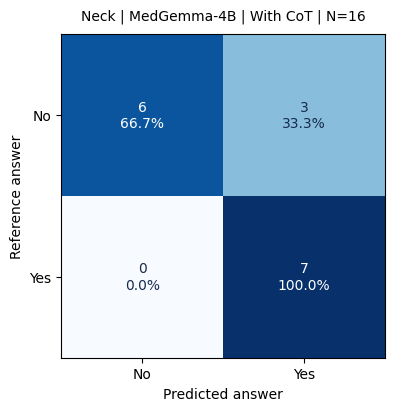

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck MedGemma-4B With   content_type       KG  6        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck MedGemma-4B With   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck MedGemma-4B With   content_type    Organ  6         66.67              66.67           80.00       62.50                 88.89              66.67          70.83   33.3/100.0/50.0   100.0/60.0/75.0        0
   Neck MedGemma-4B With   content_type    Plane  1        100.00       

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [1/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [2/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [3/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [4/16] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [5/16] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [6/16] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [7/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [8/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [9/16] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [10/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [11/16] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [12/16] gold='yes' pred='__invalid__' raw='The image sh

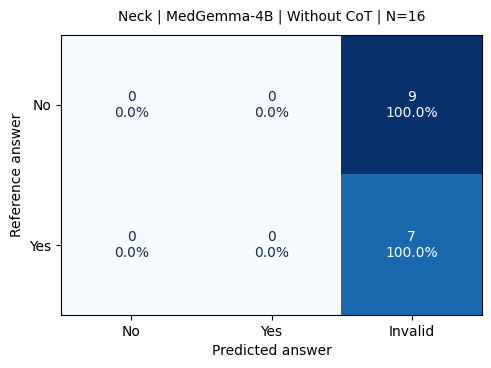

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted) Yes-class P/R/F1 No-class P/R/F1  Invalid
   Neck MedGemma-4B Without   content_type       KG  6          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        6
   Neck MedGemma-4B Without   content_type Modality  2          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        2
   Neck MedGemma-4B Without   content_type    Organ  6          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        6
   Neck MedGemma-4B Without   content_type    Plane  1          0.00    

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [1/108] gold='no' pred='no' raw='No'
    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No'
    [4/108] gold='yes' pred='yes' raw='Yes'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='no' raw='No'
    [7/108] gold='no' pred='no' raw='No'
    [8/108] gold='no' pred='no' raw='No'
    [9/108] gold='yes' pred='yes' raw='Yes'
    [10/108] gold='yes' pred='yes' raw='Yes'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No'
    [13/108] gold='no' pred='no' raw='No'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='yes' raw='Yes'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No'
    [21/108] gold='no' pred='no' raw='No'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='yes' raw='Yes'
    

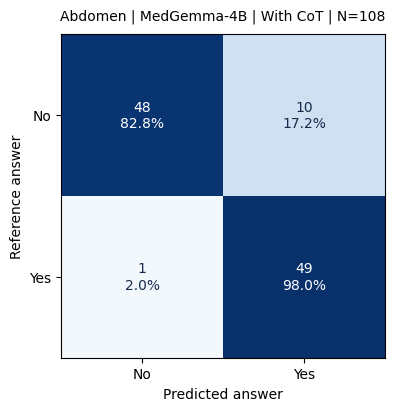

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name  CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
Abdomen MedGemma-4B With   content_type Abnormality  9        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
Abdomen MedGemma-4B With   content_type          KG 17         94.12              95.00           93.75       94.04                 94.71              94.12          94.08   90.0/100.0/94.7   100.0/87.5/93.3        0
Abdomen MedGemma-4B With   content_type       Organ 81         87.65              88.42           88.61       87.65                 89.41              87.65          87.67    79.5/97.2/87.5    97.3/80.0/87.8        0
Abdomen MedGemma-4B With   content_type       Plane  1      

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [1/108] gold='no' pred='__invalid__' raw='The image shows the chest, including the'
    [2/108] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [3/108] gold='no' pred='__invalid__' raw='The image shows a CT scan of the'
    [4/108] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [5/108] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [6/108] gold='no' pred='__invalid__' raw='The image shows a cross-sectional view'
    [7/108] gold='no' pred='__invalid__' raw='The image shows an abdominal CT scan.'
    [8/108] gold='no' pred='__invalid__' raw='The image shows an abdominal CT scan.'
    [9/108] gold='yes' pred='__invalid__' raw='The liver appears to be of normal size'
    [10/108] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [11/108] gold='yes' pred='__invalid__' raw='The image shows a cross-sectional view'
    [12/108] gold='no' pred='__invalid__' raw='The i

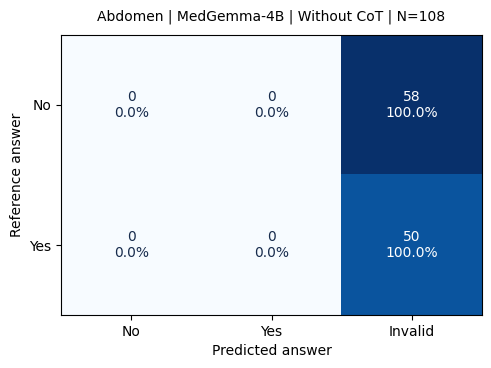

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name     CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted) Yes-class P/R/F1 No-class P/R/F1  Invalid
Abdomen MedGemma-4B Without   content_type Abnormality  9          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0        9
Abdomen MedGemma-4B Without   content_type          KG 17          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0       17
Abdomen MedGemma-4B Without   content_type       Organ 81          0.00               0.00            0.00        0.00                  0.00               0.00           0.00      0.0/0.0/0.0     0.0/0.0/0.0       81
Abdomen MedGemma-4B Without   content_type       Plane  1   

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (14 outputs left out)

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


    [1/12] gold='yes' pred='yes' raw='Yes'


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/12] gold='no' pred='no' raw='No'
    [3/12] gold='yes' pred='no' raw='No'
    [4/12] gold='no' pred='no' raw='No'
    [5/12] gold='no' pred='no' raw='No'
    [6/12] gold='no' pred='no' raw='No'
    [7/12] gold='yes' pred='yes' raw='Yes'
    [8/12] gold='no' pred='no' raw='No'
    [9/12] gold='yes' pred='yes' raw='Yes'
    [10/12] gold='yes' pred='yes' raw='Yes'
    [11/12] gold='no' pred='no' raw='No'
    [12/12] gold='no' pred='no' raw='No'
Classification report -- Qwen2.5-VL-7B (With CoT, BrainFace):
              precision    recall  f1-score   support

          no     0.8750    1.0000    0.9333         7
         yes     1.0000    0.8000    0.8889         5

    accuracy                         0.9167        12
   macro avg     0.9375    0.9000    0.9111        12
weighted avg     0.9271    0.9167    0.9148        12

Accuracy: 91.67% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Yes
No    7    0
Yes   1    4


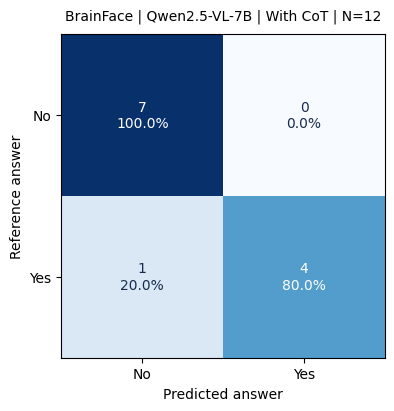

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset    Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace Qwen2.5-VL-7B With   content_type       KG  4        100.00              50.00           50.00       50.00                100.00             100.00         100.00       0.0/0.0/0.0 100.0/100.0/100.0        0
BrainFace Qwen2.5-VL-7B With   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace Qwen2.5-VL-7B With   content_type    Organ  5         80.00              83.33           83.33       80.00                 86.67              80.00          80.00   100.0/66.7/80.0   66.7/100.0/80.0        0
BrainFace Qwen2.5-VL-7B With   content_type    Plane  1 

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/12] gold='no' pred='no' raw='No'
    [3/12] gold='yes' pred='yes' raw='Yes'
    [4/12] gold='no' pred='no' raw='No'
    [5/12] gold='no' pred='no' raw='No'
    [6/12] gold='no' pred='no' raw='No'
    [7/12] gold='yes' pred='yes' raw='Yes'
    [8/12] gold='no' pred='no' raw='No'
    [9/12] gold='yes' pred='yes' raw='Yes'
    [10/12] gold='yes' pred='yes' raw='Yes'
    [11/12] gold='no' pred='no' raw='No'
    [12/12] gold='no' pred='no' raw='No'
Classification report -- Qwen2.5-VL-7B (Without CoT, BrainFace):
              precision    recall  f1-score   support

          no     1.0000    1.0000    1.0000         7
         yes     1.0000    1.0000    1.0000         5

    accuracy                         1.0000        12
   macro avg     1.0000    1.0000    1.0000        12
weighted avg     1.0000    1.0000    1.0000        12

Accuracy: 100.00% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Yes
No    7    0
Yes   0    5


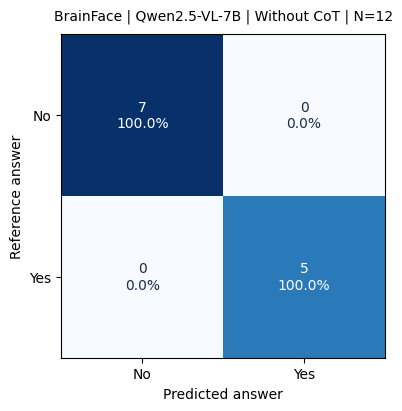

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset    Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace Qwen2.5-VL-7B Without   content_type       KG  4        100.00              50.00           50.00       50.00                100.00             100.00         100.00       0.0/0.0/0.0 100.0/100.0/100.0        0
BrainFace Qwen2.5-VL-7B Without   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace Qwen2.5-VL-7B Without   content_type    Organ  5        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
BrainFace Qwen2.5-VL-7B Without   content_ty

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/16] gold='no' pred='no' raw='No'
    [3/16] gold='no' pred='no' raw='No'
    [4/16] gold='yes' pred='no' raw='No'
    [5/16] gold='yes' pred='yes' raw='Yes'
    [6/16] gold='yes' pred='yes' raw='Yes'
    [7/16] gold='no' pred='no' raw='No'
    [8/16] gold='no' pred='no' raw='No'
    [9/16] gold='yes' pred='no' raw='No'
    [10/16] gold='no' pred='no' raw='No'
    [11/16] gold='no' pred='no' raw='No'
    [12/16] gold='yes' pred='yes' raw='Yes'
    [13/16] gold='yes' pred='yes' raw='Yes'
    [14/16] gold='no' pred='no' raw='No'
    [15/16] gold='no' pred='no' raw='No'
    [16/16] gold='yes' pred='no' raw='No'
Classification report -- Qwen2.5-VL-7B (With CoT, Neck):
              precision    recall  f1-score   support

          no     0.7500    1.0000    0.8571         9
         yes     1.0000    0.5714    0.7273         7

    accuracy                         0.8125        16
   macro avg     0.8750    0.7857    0.7922        16
weighted avg     0.8594    0.8125    0.8003      

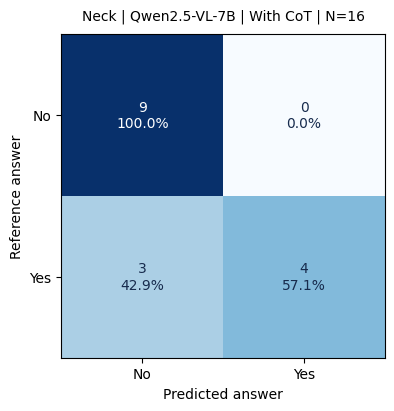

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset    Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck Qwen2.5-VL-7B With   content_type       KG  6         50.00              70.00           62.50       48.57                 80.00              50.00          45.71   100.0/25.0/40.0   40.0/100.0/57.1        0
   Neck Qwen2.5-VL-7B With   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Qwen2.5-VL-7B With   content_type    Organ  6        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Qwen2.5-VL-7B With   content_type    Plane  1        100

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/16] gold='no' pred='yes' raw='Yes'
    [3/16] gold='no' pred='yes' raw='Yes'
    [4/16] gold='yes' pred='no' raw='No'
    [5/16] gold='yes' pred='no' raw='No'
    [6/16] gold='yes' pred='yes' raw='Yes'
    [7/16] gold='no' pred='no' raw='No'
    [8/16] gold='no' pred='no' raw='No'
    [9/16] gold='yes' pred='no' raw='No'
    [10/16] gold='no' pred='no' raw='No'
    [11/16] gold='no' pred='no' raw='No'
    [12/16] gold='yes' pred='yes' raw='Yes'
    [13/16] gold='yes' pred='no' raw='No'
    [14/16] gold='no' pred='no' raw='No'
    [15/16] gold='no' pred='no' raw='No'
    [16/16] gold='yes' pred='no' raw='No'
Classification report -- Qwen2.5-VL-7B (Without CoT, Neck):
              precision    recall  f1-score   support

          no     0.5833    0.7778    0.6667         9
         yes     0.5000    0.2857    0.3636         7

    accuracy                         0.5625        16
   macro avg     0.5417    0.5317    0.5152        16
weighted avg     0.5469    0.5625    0.5341   

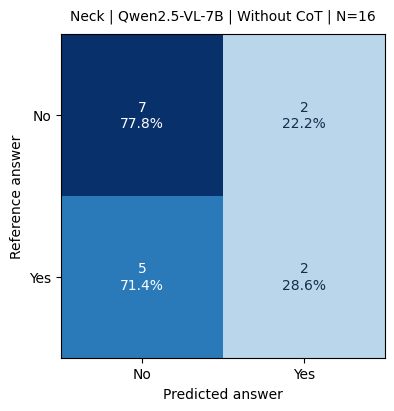

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset    Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck Qwen2.5-VL-7B Without   content_type       KG  6         33.33              16.67           50.00       25.00                 11.11              33.33          16.67       0.0/0.0/0.0   33.3/100.0/50.0        0
   Neck Qwen2.5-VL-7B Without   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Qwen2.5-VL-7B Without   content_type    Organ  6         50.00              37.50           30.00       33.33                 62.50              50.00          55.56       0.0/0.0/0.0    75.0/60.0/66.7        0
   Neck Qwen2.5-VL-7B Without   content_type    Plan

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No'
    [4/108] gold='yes' pred='yes' raw='Yes'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='no' raw='No'
    [7/108] gold='no' pred='no' raw='No'
    [8/108] gold='no' pred='no' raw='No'
    [9/108] gold='yes' pred='yes' raw='Yes'
    [10/108] gold='yes' pred='yes' raw='Yes'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No'
    [13/108] gold='no' pred='no' raw='No'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='yes' raw='Yes'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No'
    [21/108] gold='no' pred='no' raw='No'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='no' raw='No'
    [24/108] gold='yes' pred='yes' raw='Yes'
  

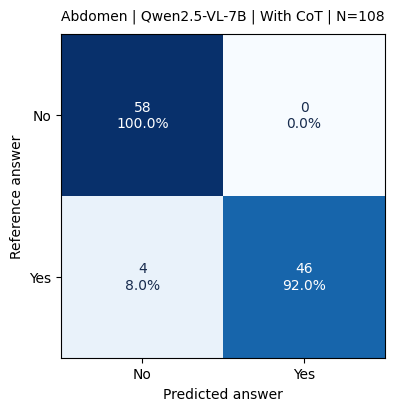

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset    Model Name  CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
Abdomen Qwen2.5-VL-7B With   content_type Abnormality  9        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
Abdomen Qwen2.5-VL-7B With   content_type          KG 17         82.35              86.36           83.33       82.11                 87.17              82.35          81.98   100.0/66.7/80.0   72.7/100.0/84.2        0
Abdomen Qwen2.5-VL-7B With   content_type       Organ 81         98.77              98.91           98.61       98.75                 98.79              98.77          98.76   100.0/97.2/98.6   97.8/100.0/98.9        0
Abdomen Qwen2.5-VL-7B With   content_type       Plan

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No'
    [4/108] gold='yes' pred='yes' raw='Yes'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='yes' raw='Yes'
    [7/108] gold='no' pred='no' raw='No'
    [8/108] gold='no' pred='no' raw='No'
    [9/108] gold='yes' pred='no' raw='No'
    [10/108] gold='yes' pred='no' raw='No'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No'
    [13/108] gold='no' pred='no' raw='No'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='no' raw='No'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No'
    [21/108] gold='no' pred='no' raw='No'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='yes' raw='Yes'
    [24/108] gold='yes' pred='yes' raw='Yes'
    

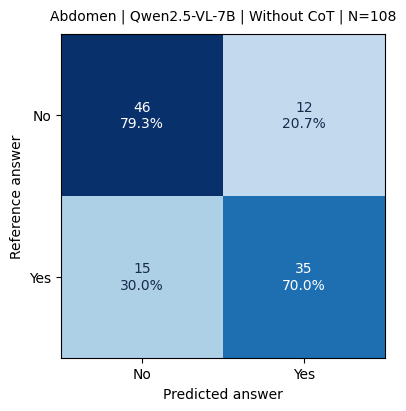

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset    Model Name     CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1 No-class P/R/F1  Invalid
Abdomen Qwen2.5-VL-7B Without   content_type Abnormality  9         55.56              27.78           50.00       35.71                 30.86              55.56          39.68       0.0/0.0/0.0 55.6/100.0/71.4        0
Abdomen Qwen2.5-VL-7B Without   content_type          KG 17         52.94              55.00           54.17       51.43                 55.29              52.94          50.92    60.0/33.3/42.9  50.0/75.0/60.0        0
Abdomen Qwen2.5-VL-7B Without   content_type       Organ 81         81.48              81.55           81.94       81.44                 82.22              81.48          81.54    75.6/86.1/80.5  87.5/77.8/82.4        0
Abdomen Qwen2.5-VL-7B Without   content_type    

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (12 outputs left out)

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]


--- Qwen3-VL-8B | CoT: With | BrainFace | closed ---
    [1/12] gold='yes' pred='yes' raw='Yes'


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/12] gold='no' pred='no' raw='No'
    [3/12] gold='yes' pred='no' raw='No'
    [4/12] gold='no' pred='no' raw='No'
    [5/12] gold='no' pred='no' raw='No'
    [6/12] gold='no' pred='no' raw='No'
    [7/12] gold='yes' pred='yes' raw='Yes'
    [8/12] gold='no' pred='no' raw='No'
    [9/12] gold='yes' pred='yes' raw='Yes'
    [10/12] gold='yes' pred='yes' raw='Yes'
    [11/12] gold='no' pred='no' raw='No'
    [12/12] gold='no' pred='no' raw='No'
Classification report -- Qwen3-VL-8B (With CoT, BrainFace):
              precision    recall  f1-score   support

          no     0.8750    1.0000    0.9333         7
         yes     1.0000    0.8000    0.8889         5

    accuracy                         0.9167        12
   macro avg     0.9375    0.9000    0.9111        12
weighted avg     0.9271    0.9167    0.9148        12

Accuracy: 91.67% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Yes
No    7    0
Yes   1    4


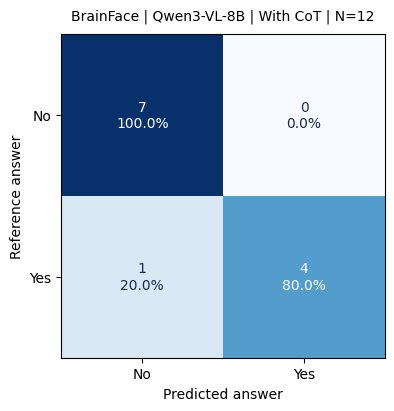

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset  Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace Qwen3-VL-8B With   content_type       KG  4        100.00              50.00           50.00       50.00                100.00             100.00         100.00       0.0/0.0/0.0 100.0/100.0/100.0        0
BrainFace Qwen3-VL-8B With   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace Qwen3-VL-8B With   content_type    Organ  5         80.00              83.33           83.33       80.00                 86.67              80.00          80.00   100.0/66.7/80.0   66.7/100.0/80.0        0
BrainFace Qwen3-VL-8B With   content_type    Plane  1        100

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/12] gold='no' pred='no' raw='No'
    [3/12] gold='yes' pred='no' raw='No'
    [4/12] gold='no' pred='no' raw='No'
    [5/12] gold='no' pred='no' raw='No'
    [6/12] gold='no' pred='yes' raw='Yes'
    [7/12] gold='yes' pred='yes' raw='Yes'
    [8/12] gold='no' pred='no' raw='No'
    [9/12] gold='yes' pred='yes' raw='Yes'
    [10/12] gold='yes' pred='no' raw='No'
    [11/12] gold='no' pred='no' raw='No'
    [12/12] gold='no' pred='no' raw='No'
Classification report -- Qwen3-VL-8B (Without CoT, BrainFace):
              precision    recall  f1-score   support

          no     0.7500    0.8571    0.8000         7
         yes     0.7500    0.6000    0.6667         5

    accuracy                         0.7500        12
   macro avg     0.7500    0.7286    0.7333        12
weighted avg     0.7500    0.7500    0.7444        12

Accuracy: 75.00% | Invalid outputs: 0
Confusion matrix: counts (rows = reference, columns = prediction)
     No  Yes
No    6    1
Yes   2    3


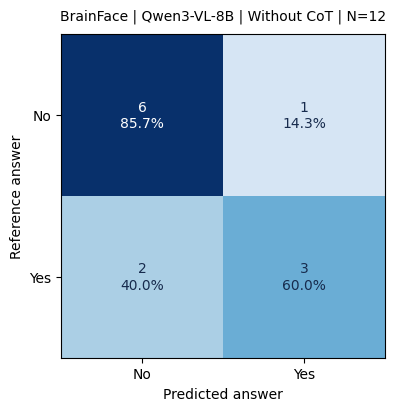

CATEGORY RESULTS -- rows are grouped separately for each category field
  Dataset  Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
BrainFace Qwen3-VL-8B Without   content_type       KG  4         75.00              50.00           37.50       42.86                100.00              75.00          85.71       0.0/0.0/0.0   100.0/75.0/85.7        0
BrainFace Qwen3-VL-8B Without   content_type Modality  1        100.00              50.00           50.00       50.00                100.00             100.00         100.00 100.0/100.0/100.0       0.0/0.0/0.0        0
BrainFace Qwen3-VL-8B Without   content_type    Organ  5         60.00              75.00           66.67       58.33                 80.00              60.00          56.67   100.0/33.3/50.0   50.0/100.0/66.7        0
BrainFace Qwen3-VL-8B Without   content_type    Plan

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/16] gold='no' pred='no' raw='No'
    [3/16] gold='no' pred='no' raw='No'
    [4/16] gold='yes' pred='no' raw='No'
    [5/16] gold='yes' pred='yes' raw='Yes'
    [6/16] gold='yes' pred='yes' raw='Yes'
    [7/16] gold='no' pred='no' raw='No'
    [8/16] gold='no' pred='no' raw='No'
    [9/16] gold='yes' pred='no' raw='No'
    [10/16] gold='no' pred='no' raw='No'
    [11/16] gold='no' pred='no' raw='No'
    [12/16] gold='yes' pred='yes' raw='Yes'
    [13/16] gold='yes' pred='yes' raw='Yes'
    [14/16] gold='no' pred='no' raw='No'
    [15/16] gold='no' pred='no' raw='No'
    [16/16] gold='yes' pred='yes' raw='Yes'
Classification report -- Qwen3-VL-8B (With CoT, Neck):
              precision    recall  f1-score   support

          no     0.8182    1.0000    0.9000         9
         yes     1.0000    0.7143    0.8333         7

    accuracy                         0.8750        16
   macro avg     0.9091    0.8571    0.8667        16
weighted avg     0.8977    0.8750    0.8708      

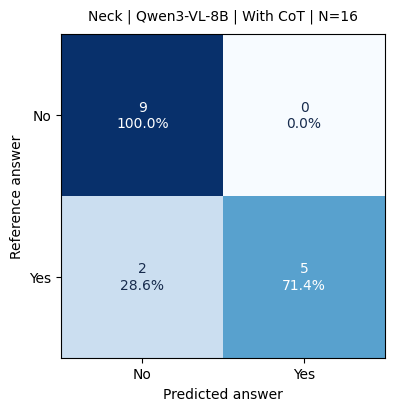

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name  CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck Qwen3-VL-8B With   content_type       KG  6         66.67              75.00           75.00       66.67                 83.33              66.67          66.67   100.0/50.0/66.7   50.0/100.0/66.7        0
   Neck Qwen3-VL-8B With   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Qwen3-VL-8B With   content_type    Organ  6        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Qwen3-VL-8B With   content_type    Plane  1        100.00       

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/16] gold='no' pred='yes' raw='Yes'
    [3/16] gold='no' pred='yes' raw='Yes'
    [4/16] gold='yes' pred='no' raw='No'
    [5/16] gold='yes' pred='no' raw='No'
    [6/16] gold='yes' pred='yes' raw='Yes'
    [7/16] gold='no' pred='no' raw='No'
    [8/16] gold='no' pred='no' raw='No'
    [9/16] gold='yes' pred='yes' raw='Yes'
    [10/16] gold='no' pred='no' raw='No'
    [11/16] gold='no' pred='no' raw='No'
    [12/16] gold='yes' pred='yes' raw='Yes'
    [13/16] gold='yes' pred='no' raw='No'
    [14/16] gold='no' pred='no' raw='No'
    [15/16] gold='no' pred='no' raw='No'
    [16/16] gold='yes' pred='yes' raw='Yes'
Classification report -- Qwen3-VL-8B (Without CoT, Neck):
              precision    recall  f1-score   support

          no     0.7000    0.7778    0.7368         9
         yes     0.6667    0.5714    0.6154         7

    accuracy                         0.6875        16
   macro avg     0.6833    0.6746    0.6761        16
weighted avg     0.6854    0.6875    0.6837 

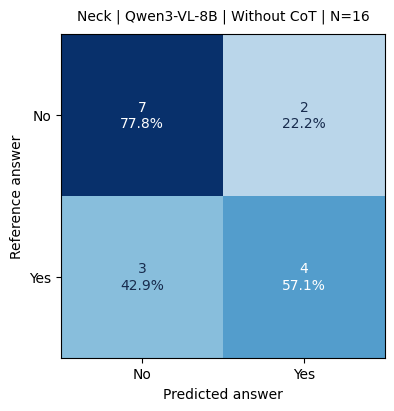

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name     CoT Category field Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1   No-class P/R/F1  Invalid
   Neck Qwen3-VL-8B Without   content_type       KG  6         66.67              75.00           75.00       66.67                 83.33              66.67          66.67   100.0/50.0/66.7   50.0/100.0/66.7        0
   Neck Qwen3-VL-8B Without   content_type Modality  2        100.00             100.00          100.00      100.00                100.00             100.00         100.00 100.0/100.0/100.0 100.0/100.0/100.0        0
   Neck Qwen3-VL-8B Without   content_type    Organ  6         50.00              37.50           30.00       33.33                 62.50              50.00          55.56       0.0/0.0/0.0    75.0/60.0/66.7        0
   Neck Qwen3-VL-8B Without   content_type    Plane  1      

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No'
    [4/108] gold='yes' pred='yes' raw='Yes'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='no' raw='No'
    [7/108] gold='no' pred='no' raw='No'
    [8/108] gold='no' pred='no' raw='No'
    [9/108] gold='yes' pred='yes' raw='Yes'
    [10/108] gold='yes' pred='yes' raw='Yes'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No'
    [13/108] gold='no' pred='no' raw='No'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='yes' raw='Yes'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No'
    [21/108] gold='no' pred='no' raw='No'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='yes' raw='Yes'
    [24/108] gold='yes' pred='yes' raw='Yes'


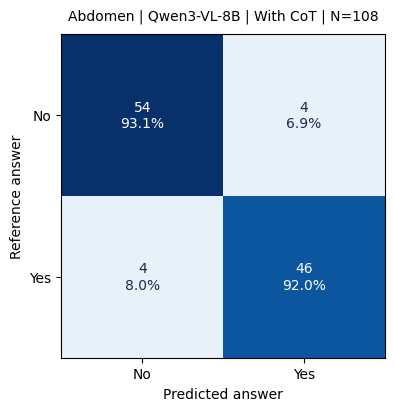

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name  CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1 No-class P/R/F1  Invalid
Abdomen Qwen3-VL-8B With   content_type Abnormality  9         88.89              91.67           87.50       88.31                 90.74              88.89          88.60   100.0/75.0/85.7 83.3/100.0/90.9        0
Abdomen Qwen3-VL-8B With   content_type          KG 17         88.24              88.19           88.19       88.19                 88.24              88.24          88.24    88.9/88.9/88.9  87.5/87.5/87.5        0
Abdomen Qwen3-VL-8B With   content_type       Organ 81         93.83              93.67           93.89       93.77                 93.87              93.83          93.83    91.9/94.4/93.2  95.5/93.3/94.4        0
Abdomen Qwen3-VL-8B With   content_type       Plane  1        100.00

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


    [2/108] gold='yes' pred='yes' raw='Yes'
    [3/108] gold='no' pred='no' raw='No'
    [4/108] gold='yes' pred='no' raw='No'
    [5/108] gold='yes' pred='yes' raw='Yes'
    [6/108] gold='no' pred='no' raw='No'
    [7/108] gold='no' pred='no' raw='No'
    [8/108] gold='no' pred='no' raw='No'
    [9/108] gold='yes' pred='no' raw='No'
    [10/108] gold='yes' pred='no' raw='No'
    [11/108] gold='yes' pred='yes' raw='Yes'
    [12/108] gold='no' pred='no' raw='No'
    [13/108] gold='no' pred='no' raw='No'
    [14/108] gold='yes' pred='yes' raw='Yes'
    [15/108] gold='yes' pred='yes' raw='Yes'
    [16/108] gold='yes' pred='no' raw='No'
    [17/108] gold='yes' pred='yes' raw='Yes'
    [18/108] gold='no' pred='no' raw='No'
    [19/108] gold='yes' pred='yes' raw='Yes'
    [20/108] gold='yes' pred='no' raw='No'
    [21/108] gold='no' pred='no' raw='No'
    [22/108] gold='yes' pred='yes' raw='Yes'
    [23/108] gold='no' pred='yes' raw='Yes'
    [24/108] gold='yes' pred='yes' raw='Yes'
    [25/

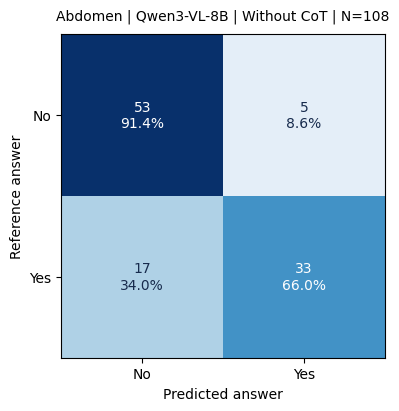

CATEGORY RESULTS -- rows are grouped separately for each category field
Dataset  Model Name     CoT Category field    Category  N  Accuracy (%)  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  Yes-class P/R/F1 No-class P/R/F1  Invalid
Abdomen Qwen3-VL-8B Without   content_type Abnormality  9         55.56              27.78           50.00       35.71                 30.86              55.56          39.68       0.0/0.0/0.0 55.6/100.0/71.4        0
Abdomen Qwen3-VL-8B Without   content_type          KG 17         70.59              73.48           71.53       70.18                 74.06              70.59          69.97    83.3/55.6/66.7  63.6/87.5/73.7        0
Abdomen Qwen3-VL-8B Without   content_type       Organ 81         83.95              84.55           83.06       83.46                 84.27              83.95          83.77    87.1/75.0/80.6  82.0/91.1/86.3        0
Abdomen Qwen3-VL-8B Without   content_type       Plane  

preprocessor_config.json:   0%|          | 0.00/477 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/477 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

... (7 outputs left out)

model-00002-of-00005.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00005-of-00005.safetensors:   0%|          | 0.00/1.47G [00:00<?, ?B/s]

GPU 0: allocated=0.01 GiB, reserved=2.23 GiB
GPU 1: allocated=0.01 GiB, reserved=4.99 GiB


RuntimeError: Stopped at closed/Llama-11B. Completed rows are saved. Fix the error and rerun to resume: I/O error: IO Error: No space left on device (os error 28)

In [8]:
# 5. Resumable row checkpoints; changes to data, prompts or models invalidate old results.
@lru_cache(maxsize=None)
def image_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

@lru_cache(maxsize=None)
def signature(dataset, task, name, condition):
    payload = {'version': 1, 'repo': MODELS[name], 'revision': REVISIONS[name],
               'tokens': MAX_NEW_TOKENS[task], 'image_side': MAX_IMAGE_SIDE,
               'dtype': str(COMPUTE_DTYPE), 'transformers': version('transformers'),
               'bitsandbytes': version('bitsandbytes'),
               'rows': [{'image': image_hash(r['img_path']), 'gold': r['gold'],
                         'prompt': make_prompt(r, task, condition)} for r in TEST[dataset, task]]}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def result_path(dataset, task, name, condition):
    return RAW_DIR/f'{dataset}__{task}__{name}__{condition}.json'

def checkpoint(dataset, task, name, condition):
    target = result_path(dataset, task, name, condition)
    expected = signature(dataset, task, name, condition)
    best = {'signature': expected, 'repo': MODELS[name], 'revision': REVISIONS[name], 'rows': []}
    for path in [target, *(Path(d)/target.name for d in RESUME_RAW_DIRS)]:
        if not path.exists():
            continue
        with open(path, encoding='utf-8') as f:
            saved = json.load(f)
        rows = saved.get('rows', [])
        if (saved.get('signature') == expected and len(rows) <= len(TEST[dataset, task])
                and all(r.get('row') == i and 'raw' in r for i, r in enumerate(rows))
                and len(rows) > len(best['rows'])):
            best = saved
    return best

def save_checkpoint(path, value):
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(temp, path)

def closed_metrics(rows, verbose=False):
    gold, pred = [r['gold'] for r in rows], [r['pred'] for r in rows]
    p, r, f, support = precision_recall_fscore_support(gold, pred, labels=['no', 'yes'], zero_division=0)
    accuracy = accuracy_score(gold, pred)
    if verbose:
        print(classification_report(gold, pred, labels=['no', 'yes'], zero_division=0, digits=4))
        print(f'Accuracy: {accuracy*100:.2f}% | Invalid outputs: {pred.count("__invalid__")}')
    return {'Accuracy (%)': accuracy*100, 'Precision (macro)': p.mean()*100,
            'Recall (macro)': r.mean()*100, 'F1 (macro)': f.mean()*100,
            'Precision (weighted)': float((p*support).sum()/support.sum()*100),
            'Recall (weighted)': float((r*support).sum()/support.sum()*100),
            'F1 (weighted)': float((f*support).sum()/support.sum()*100),
            'Yes-class P/R/F1': '/'.join(f'{v*100:.1f}' for v in (p[1],r[1],f[1])),
            'No-class P/R/F1': '/'.join(f'{v*100:.1f}' for v in (p[0],r[0],f[0])),
            'Invalid': pred.count('__invalid__')}



def rows_for_report(dataset, task, rows):
    # Attach current CSV metadata without rerunning valid cached predictions.
    return [{**row, 'categories': TEST[dataset,task][row['row']].get('categories', {})}
            for row in rows]

def category_groups(rows):
    for column in CATEGORY_COLUMNS:
        values = sorted({r.get('categories', {}).get(column) for r in rows
                         if column in r.get('categories', {})})
        for value in values:
            yield column, value, [r for r in rows if r.get('categories', {}).get(column) == value]

def confusion_counts(rows):
    # Rows: true No/Yes. Columns: predicted No/Yes, and Invalid if present.
    labels = ['no','yes']
    if any(r['pred'] not in labels for r in rows):
        labels.append('__invalid__')
    matrix = np.zeros((2,len(labels)), dtype=int)
    for row in rows:
        prediction = row['pred'] if row['pred'] in ('no','yes') else '__invalid__'
        matrix[['no','yes'].index(row['gold']), labels.index(prediction)] += 1
    assert int(matrix.sum()) == len(rows)
    return matrix, ['Invalid' if x == '__invalid__' else x.title() for x in labels]

def draw_confusion(ax, rows, title):
    matrix, labels = confusion_counts(rows)
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(1,int(matrix.max())))
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks([0,1], ['No','Yes'])
    ax.set_xlabel('Predicted answer')
    ax.set_ylabel('Reference answer')
    ax.set_title(title, fontsize=10, pad=10)
    for i in range(2):
        total = int(matrix[i].sum())
        for j in range(len(labels)):
            value = int(matrix[i,j])
            text = f'{value}\n{value/total:.1%}' if total else '0\nN/A'
            ax.text(j,i,text,ha='center',va='center',fontsize=10,
                    color='white' if value > matrix.max()/2 else '#172b4d')

def print_closed_report(dataset, name, condition, rows):
    rows = rows_for_report(dataset, 'closed', rows)
    print(f'Classification report -- {name} ({condition} CoT, {dataset}):')
    metrics = closed_metrics(rows, verbose=True)
    matrix, labels = confusion_counts(rows)
    print('Confusion matrix: counts (rows = reference, columns = prediction)')
    matrix_df = pd.DataFrame(matrix, index=['No','Yes'], columns=labels)
    print(matrix_df.to_string())
    stem = f'{dataset}__{name}__{condition}'
    matrix_df.to_csv(FIGURES_DIR/f'{stem}.csv', index_label='Reference')
    fig, ax = plt.subplots(figsize=(4.8,4.0), layout='constrained')
    draw_confusion(ax,rows,f'{dataset} | {name} | {condition} CoT | N={len(rows)}')
    fig.savefig(FIGURES_DIR/f'{stem}.png',dpi=220,bbox_inches='tight')
    fig.savefig(FIGURES_DIR/f'{stem}.pdf',bbox_inches='tight')
    plt.show()
    plt.close(fig)
    categories = [{'Dataset': dataset, 'Model Name': name, 'CoT': condition,
                   'Category field': col, 'Category': val, 'N': len(group), **closed_metrics(group)}
                  for col,val,group in category_groups(rows)]
    if categories:
        table = pd.DataFrame(categories)
        print('CATEGORY RESULTS -- rows are grouped separately for each category field')
        print(table.to_string(index=False,float_format=lambda v:f'{v:.2f}'))
    return metrics


def save_progress():
    progress = []
    for d in DATASETS:
        for t in TASKS:
            for m in MODELS:
                for c in CONDITIONS:
                    rows = checkpoint(d,t,m,c)['rows']
                    total = len(TEST[d,t])
                    progress.append({'Dataset': d, 'Task': t, 'Model': m, 'CoT': c,
                                     'Completed rows': len(rows), 'Total rows': total,
                                     'Status': 'Complete' if len(rows) == total else 'Pending'})
    table = pd.DataFrame(progress)
    table.to_csv(RESULTS_DIR/'evaluation_progress.csv', index=False)
    completed = int(table['Status'].eq('Complete').sum())
    print(f'Overall progress: {completed}/{EXPECTED_EVALUATIONS} complete evaluations', flush=True)

def release_memory():
    """Call only after model and processor references have been released."""
    plt.close("all")
    gc.collect()
    if torch.cuda.is_available():
        for device_index in range(torch.cuda.device_count()):
            with torch.cuda.device(device_index):
                torch.cuda.empty_cache()
            allocated = torch.cuda.memory_allocated(device_index) / 1024**3
            reserved = torch.cuda.memory_reserved(device_index) / 1024**3
            print(f"GPU {device_index}: allocated={allocated:.2f} GiB, "
                  f"reserved={reserved:.2f} GiB", flush=True)


def save_closed_stage_summary():
    entries = []
    for dataset in RUN_DATASETS:
        for name in RUN_MODELS:
            for condition in CONDITIONS:
                rows = checkpoint(dataset, "closed", name, condition)["rows"]
                if len(rows) != len(TEST[dataset, "closed"]):
                    raise RuntimeError(f"Incomplete closed evaluation: {dataset}/{name}/{condition}")
                entries.append({"Dataset": dataset, "Model Name": name,
                                "CoT": condition, "N": len(rows), **closed_metrics(rows)})
    table = pd.DataFrame(entries)
    scope = "ALL ELIGIBLE ROWS" if MAX_ROWS_PER_DATASET is None else "SMOKE TEST"
    print(f"\nCLOSED STAGE COMPLETED -- {len(table)} evaluations -- {scope}")
    print(table.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
    table.to_csv(RESULTS_DIR / "closed_stage_summary_ALL.csv", index=False)
    for dataset in RUN_DATASETS:
        subset = table[table["Dataset"].eq(dataset)]
        print(f"\nCLOSED SUMMARY -- {dataset} -- all selected models and both conditions")
        print(subset.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
        subset.to_csv(RESULTS_DIR / f"closed_stage_summary_{dataset}.csv", index=False)


save_progress()
# All closed questions across every model/dataset finish BEFORE open inference.
ordered_tasks = ["closed"] if "closed" in RUN_TASKS else []
for task in ordered_tasks:
    print("\n" + "=" * 100)
    print(f"STARTING {task.upper()} EVALUATION -- ALL SELECTED MODELS AND DATASETS")
    print("=" * 100)
    for name in RUN_MODELS:
        jobs = [(dataset, task, name, condition)
                for dataset in RUN_DATASETS for condition in CONDITIONS]
        pending = [job for job in jobs
                   if len(checkpoint(*job)["rows"]) != len(TEST[job[0], task])]
        model = processor = None
        try:
            release_memory()
            if pending:
                print(f"\n--- Loading {MODELS[name]} | {task.upper()} ---", flush=True)
                model, processor = load_model(name)
            for job in jobs:
                dataset, _, _, condition = job
                saved = checkpoint(*job)
                data = TEST[dataset, task]
                print(f"\n--- {name} | CoT: {condition} | {dataset} | {task} ---", flush=True)
                for i in range(len(saved["rows"]), len(data)):
                    row = data[i]
                    raw = generate_answer(model, processor, row, task, condition)
                    pred = binary(raw) if task == "closed" else norm(raw)
                    saved["rows"].append({
                        "row": i, "source_row": row["source_row"],
                        "question": row["question"], "gold": row["gold"],
                        "pred": pred, "raw": raw,
                    })
                    save_checkpoint(result_path(*job), saved)
                    print(f"    [{i+1}/{len(data)}] gold={row['gold']!r} "
                          f"pred={pred!r} raw={raw!r}", flush=True)
                save_checkpoint(result_path(*job), saved)
                if task == "closed":
                    metrics = print_closed_report(dataset, name, condition, saved["rows"])
                    save_checkpoint(result_path(*job).with_suffix(".metrics.json"), metrics)
                else:
                    print(f"Saved {len(data)} open predictions. "
                          "BLEU/ROUGE/BERTScore follow in the metrics cell.")
                save_progress()
        except Exception as exc:
            raise RuntimeError(
                f"Stopped at {task}/{name}. Completed rows are saved. "
                f"Fix the error and rerun to resume: {exc}"
            ) from exc
        finally:
            # Release the actual objects BEFORE clearing the CUDA allocator cache.
            model = processor = None
            release_memory()

        if DELETE_MODEL_CACHE_AFTER_SUCCESS:
            owned_cache = (CACHE_ROOT / name).resolve()
            if owned_cache.parent != CACHE_ROOT.resolve():
                raise ValueError("Refusing to remove a cache outside CACHE_ROOT")
            if owned_cache.exists():
                shutil.rmtree(owned_cache)

    if task == "closed":
        save_closed_stage_summary()
    print(f"\n{task.upper()} inference stage complete.")


In [1]:

# COMPLETE CLOSED REPORT -- finished and exported BEFORE open inference starts.
closed_jobs = [(d, 'closed', m, c) for d in DATASETS for m in MODELS for c in CONDITIONS]
unfinished = [job for job in closed_jobs
              if len(checkpoint(*job)['rows']) != len(TEST[job[0], 'closed'])]
if unfinished:
    raise RuntimeError('Closed report is incomplete. Finish these evaluations before open inference: '
                       + str(unfinished))
closed_rows, category_rows = [], []
for dataset, task, name, condition in closed_jobs:
    rows = rows_for_report(dataset, task, checkpoint(dataset, task, name, condition)['rows'])
    base = {'Dataset': dataset, 'Model Name': name, 'CoT': condition}
    closed_rows.append({**base, 'N': len(rows), **closed_metrics(rows)})
    for field, value, group in category_groups(rows):
        category_rows.append({**base, 'Category field': field, 'Category': value,
                              'N': len(group), **closed_metrics(group)})
closed_table = pd.DataFrame(closed_rows)
closed_table.to_csv(RESULTS_DIR/'closed_comparison_summary_all_datasets.csv', index=False)
scope = 'ALL ELIGIBLE TEST ROWS' if MAX_ROWS_PER_DATASET is None else 'SMOKE TEST ONLY'
report_lines = [f'CLOSED EVALUATION COMPLETE -- 30/30 -- {scope}',
                'Base checkpoints. With/Without refers to supplied test CoT.',
                'All metrics are percentages. Invalid predictions remain errors.',
                'Confusion matrices show invalid predictions separately, when present.']

def emit_closed_table(title, table):
    print('\n' + '='*110 + '\n' + title + '\n' + '='*110)
    rendered = table.to_string(index=False, float_format=lambda v: f'{v:.2f}')
    print(rendered)
    display(table.style.format(precision=2))
    report_lines.extend(['\n'+title, rendered])

emit_closed_table('CLOSED SUMMARY -- ALL DATASETS AND MODELS', closed_table)
for dataset in DATASETS:
    part = closed_table[closed_table['Dataset'].eq(dataset)]
    emit_closed_table(f'CLOSED SUMMARY -- {dataset}', part)
    part.to_csv(RESULTS_DIR/f'closed_comparison_summary_{dataset}.csv', index=False)

comparison_metrics = ['Accuracy (%)', 'F1 (macro)']
compact = closed_table.pivot(index=['Dataset','Model Name'], columns='CoT', values=comparison_metrics)
for metric in comparison_metrics:
    compact[(metric,'Diff')] = compact[(metric,'With')] - compact[(metric,'Without')]
compact = compact.reindex(columns=pd.MultiIndex.from_product([comparison_metrics,['With','Without','Diff']]))
print('\nCLOSED -- WITH vs WITHOUT TEST CoT (Diff = With - Without)')
print(compact.to_string(float_format=lambda v:f'{v:.2f}'))
compact.to_csv(RESULTS_DIR/'closed_comparison_with_vs_without.csv')
report_lines.extend(['\nWITH vs WITHOUT TEST CoT',compact.to_string()])

if category_rows:
    category_table = pd.DataFrame(category_rows)
    category_table.to_csv(RESULTS_DIR/'closed_category_summary_ALL.csv',index=False)
    for (dataset,field), part in category_table.groupby(['Dataset','Category field'],sort=False):
        emit_closed_table(f'CLOSED CATEGORY RESULTS -- {dataset} -- {field}',part)
        part.to_csv(RESULTS_DIR/f'closed_categories_{dataset}_{field}.csv',index=False)
    report_lines.append('Category fields define separate partitions; do not add totals across fields.')

for dataset in DATASETS:
    fig,axes = plt.subplots(len(MODELS),len(CONDITIONS),figsize=(9,3.2*len(MODELS)),
                            squeeze=False,layout='constrained')
    for i,name in enumerate(MODELS):
        for j,condition in enumerate(CONDITIONS):
            rows = checkpoint(dataset,'closed',name,condition)['rows']
            draw_confusion(axes[i,j],rows,f'{name} | {condition} CoT | N={len(rows)}')
    fig.suptitle(f'{dataset}: closed-question base-model predictions\nCounts and percentages within each reference class',fontsize=14)
    fig.savefig(FIGURES_DIR/f'{dataset}__all_models.png',dpi=220,bbox_inches='tight')
    fig.savefig(FIGURES_DIR/f'{dataset}__all_models.pdf',bbox_inches='tight')
    plt.show()
    plt.close(fig)

(RESULTS_DIR/'FINAL_CLOSED_MODEL_SUMMARY.txt').write_text('\n'.join(report_lines),encoding='utf-8')
closed_archive = RESULTS_DIR/'closed_evaluation_report.zip'
with zipfile.ZipFile(closed_archive,'w',compression=zipfile.ZIP_DEFLATED) as report:
    files = list(RESULTS_DIR.glob('closed*.csv')) + [RESULTS_DIR/'FINAL_CLOSED_MODEL_SUMMARY.txt']
    files += list(FIGURES_DIR.glob('*')) + list(RAW_DIR.glob('*__closed__*.json'))
    files += [RESULTS_DIR/'dataset_audit.csv',RESULTS_DIR/'model_manifest.csv']
    for file in files:
        if file.is_file():
            report.write(file,file.relative_to(RESULTS_DIR))
release_memory()
print('\nCLOSED REPORT COMPLETE. Saved:', closed_archive)
print('Open-question inference can now start in the next cell.')


NameError: name 'DATASETS' is not defined

In [ ]:
# Open inference starts only after the closed report cell succeeds.

save_progress()
# All closed questions across every model/dataset finish BEFORE open inference.
ordered_tasks = ["open"] if "open" in RUN_TASKS else []
for task in ordered_tasks:
    print("\n" + "=" * 100)
    print(f"STARTING {task.upper()} EVALUATION -- ALL SELECTED MODELS AND DATASETS")
    print("=" * 100)
    for name in RUN_MODELS:
        jobs = [(dataset, task, name, condition)
                for dataset in RUN_DATASETS for condition in CONDITIONS]
        pending = [job for job in jobs
                   if len(checkpoint(*job)["rows"]) != len(TEST[job[0], task])]
        model = processor = None
        try:
            release_memory()
            if pending:
                print(f"\n--- Loading {MODELS[name]} | {task.upper()} ---", flush=True)
                model, processor = load_model(name)
            for job in jobs:
                dataset, _, _, condition = job
                saved = checkpoint(*job)
                data = TEST[dataset, task]
                print(f"\n--- {name} | CoT: {condition} | {dataset} | {task} ---", flush=True)
                for i in range(len(saved["rows"]), len(data)):
                    row = data[i]
                    raw = generate_answer(model, processor, row, task, condition)
                    pred = binary(raw) if task == "closed" else norm(raw)
                    saved["rows"].append({
                        "row": i, "source_row": row["source_row"],
                        "question": row["question"], "gold": row["gold"],
                        "pred": pred, "raw": raw,
                    })
                    save_checkpoint(result_path(*job), saved)
                    print(f"    [{i+1}/{len(data)}] gold={row['gold']!r} "
                          f"pred={pred!r} raw={raw!r}", flush=True)
                save_checkpoint(result_path(*job), saved)
                if task == "closed":
                    metrics = print_closed_report(dataset, name, condition, saved["rows"])
                    save_checkpoint(result_path(*job).with_suffix(".metrics.json"), metrics)
                else:
                    print(f"Saved {len(data)} open predictions. "
                          "BLEU/ROUGE/BERTScore follow in the metrics cell.")
                save_progress()
        except Exception as exc:
            raise RuntimeError(
                f"Stopped at {task}/{name}. Completed rows are saved. "
                f"Fix the error and rerun to resume: {exc}"
            ) from exc
        finally:
            # Release the actual objects BEFORE clearing the CUDA allocator cache.
            model = processor = None
            release_memory()

        if DELETE_MODEL_CACHE_AFTER_SUCCESS:
            owned_cache = (CACHE_ROOT / name).resolve()
            if owned_cache.parent != CACHE_ROOT.resolve():
                raise ValueError("Refusing to remove a cache outside CACHE_ROOT")
            if owned_cache.exists():
                shutil.rmtree(owned_cache)

    if task == "closed":
        save_closed_stage_summary()
    print(f"\n{task.upper()} inference stage complete.")


In [ ]:
# 6. Open metrics: same definitions as the final fine-tuned open notebook.
normalize_answer = norm
BERT_PAIR_CACHE = {}
def compute_open_metrics(results, scorer):
    references = [normalize_answer(r["gold"]) for r in results]
    predictions = [normalize_answer(r["raw"]) for r in results]
    if not references or any(not r for r in references):
        raise ValueError("Every test question must have a nonempty reference answer.")
    bleu = corpus_bleu(
        [[reference.split()] for reference in references],
        [prediction.split() for prediction in predictions],
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=SmoothingFunction().method1,
    )
    rouge = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False)
    rouge_rows = [rouge.score(reference, prediction)
                  for reference, prediction in zip(references, predictions)]
    # Empty responses must count against the model, not disappear from metrics.
    nonempty = [i for i, prediction in enumerate(predictions) if prediction]
    totals = {"P": 0.0, "R": 0.0, "F1": 0.0}
    if nonempty:
        pairs = [(predictions[i], references[i]) for i in nonempty]
        missing_pairs = list(dict.fromkeys(pair for pair in pairs if pair not in BERT_PAIR_CACHE))
        if missing_pairs:
            precision, recall, f1 = scorer.score(
                [pair[0] for pair in missing_pairs], [pair[1] for pair in missing_pairs],
                batch_size=BERTSCORE_BATCH_SIZE,
            )
            for pair, pv, rv, fv in zip(missing_pairs, precision.tolist(), recall.tolist(), f1.tolist()):
                BERT_PAIR_CACHE[pair] = (pv,rv,fv)
        totals = {key: sum(BERT_PAIR_CACHE[pair][index] for pair in pairs)
                  for index,key in enumerate(('P','R','F1'))}
    n = len(results)
    return {
        "BLEU": float(bleu),
        "ROUGE-1": sum(r["rouge1"].fmeasure for r in rouge_rows) / n,
        "ROUGE-2": sum(r["rouge2"].fmeasure for r in rouge_rows) / n,
        "ROUGE-L": sum(r["rougeL"].fmeasure for r in rouge_rows) / n,
        "BERTScore F1": totals["F1"] / n,
        "BERTScore P": totals["P"] / n,
        "BERTScore R": totals["R"] / n,
    }


required_jobs = [(d,t,m,c) for d in DATASETS for t in TASKS for m in MODELS for c in CONDITIONS]
missing = [j for j in required_jobs if len(checkpoint(*j)['rows']) != len(TEST[j[0],j[1]])]
if missing:
    raise RuntimeError(f'Final report requires all {EXPECTED_EVALUATIONS} evaluations. Remaining: '+str(missing))

closed_summary, open_summary = [], []
closed_categories, open_categories, output_diagnostics = [], [], []
for dataset, task, name, condition in required_jobs:
    if task == 'closed':
        rows = checkpoint(dataset, task, name, condition)['rows']
        rows = rows_for_report(dataset, task, rows)
        for col, val, group in category_groups(rows):
            closed_categories.append({'Dataset': dataset, 'Model Name': name, 'CoT': condition,
                'Category field': col, 'Category': val, 'N': len(group), **closed_metrics(group)})
        closed_summary.append({'Dataset': dataset, 'Model Name': name, 'CoT': condition,
                               'N': len(rows), **closed_metrics(rows)})

pd.DataFrame(closed_summary).to_csv(RESULTS_DIR/'closed_comparison_summary_all_datasets.csv', index=False)

gc.collect()
torch.cuda.empty_cache()
scorer = BERTScorer(model_type=BERTSCORE_MODEL, lang='en', device='cuda:0',
                    batch_size=BERTSCORE_BATCH_SIZE, idf=False, rescale_with_baseline=False,
                    use_fast_tokenizer=False)
metric_settings = {'BLEU': 'corpus BLEU-4, NLTK method1 smoothing',
                   'ROUGE': 'mean per-row F1, no stemming', 'BERTScore_hash': scorer.hash,
                   'BERTScore_model': BERTSCORE_MODEL, 'normalization': 'NFKC, lowercase, collapsed whitespace',
                   'versions': {p: version(p) for p in ['transformers','bitsandbytes','nltk','rouge-score','bert-score']}}
try:
    for dataset, task, name, condition in required_jobs:
        if task != 'open':
            continue
        rows = checkpoint(dataset, task, name, condition)['rows']
        rows = rows_for_report(dataset, task, rows)
        metrics = compute_open_metrics(rows, scorer)
        output_diagnostics.append({'Dataset': dataset, 'Model Name': name, 'CoT': condition,
            'N': len(rows), 'Empty': sum(not norm(r['raw']) for r in rows),
            'Over 4 words': sum(len(r['raw'].split()) > 4 for r in rows)})
        for col, val, group in category_groups(rows):
            open_categories.append({'Dataset': dataset, 'Model Name': name, 'CoT': condition,
                'Category field': col, 'Category': val, 'N': len(group),
                **compute_open_metrics(group, scorer)})
        entry = {'Dataset': dataset, 'Model Name': name, 'CoT': condition, 'N': len(rows), **metrics}
        open_summary.append(entry)
        save_checkpoint(result_path(dataset, task, name, condition).with_suffix('.metrics.json'),
                        {'metrics': metrics, 'settings': metric_settings})
        print(f'\nOpen metrics -- {name} ({condition} CoT, {dataset}):')
        print(pd.DataFrame([entry]).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
        pd.DataFrame(open_summary).to_csv(RESULTS_DIR/'open_summary_progress.csv', index=False)
finally:
    scorer = None
    gc.collect()
    torch.cuda.empty_cache()
(RESULTS_DIR/'metric_settings.json').write_text(json.dumps(metric_settings, indent=2), encoding='utf-8')


In [ ]:
# 7. FINAL SUMMARY: all models, datasets, conditions and metrics.
closed_df, open_df = pd.DataFrame(closed_summary), pd.DataFrame(open_summary)
assert len(closed_df) == 30 and len(open_df) == 30
label = 'ALL ELIGIBLE TEST ROWS' if MAX_ROWS_PER_DATASET is None else f'SMOKE TEST ONLY: up to {MAX_ROWS_PER_DATASET} rows'
for task, table in [('closed', closed_df), ('open', open_df)]:
    table.to_csv(RESULTS_DIR/f'{task}_comparison_summary_all_datasets.csv', index=False)
    digits = 2 if task == 'closed' else 4
    print('\n' + '='*120)
    print(f'ALL DATASETS -- {task.upper()} -- {len(table)} EVALUATIONS -- {label}')
    print('='*120)
    print(table.to_string(index=False, float_format=lambda v: f'{v:.{digits}f}'))
    display(table.style.format(precision=digits))
    for dataset in DATASETS:
        subset = table[table['Dataset'].eq(dataset)]
        print('\n'+'='*120)
        print(f'{task.upper()} SUMMARY -- {dataset} -- {label} -- BASE CHECKPOINTS / TEST-TIME CoT')
        print('='*120)
        digits = 2 if task == 'closed' else 4
        print(subset.to_string(index=False, float_format=lambda v: f'{v:.{digits}f}'))
        display(subset.style.format(precision=digits))
        subset.to_csv(RESULTS_DIR/f'{task}_comparison_summary_{dataset}.csv', index=False)
print('\nSaved summaries, dataset audit, metric settings and per-question predictions:', RESULTS_DIR)
print('Closed metrics are percentages. Open metrics are on their original scale, not percentages.')
print('With/Without means supplied test CoT; both conditions use identical rows for each dataset/task.')
if MAX_ROWS_PER_DATASET is not None:
    print('Set MAX_ROWS_PER_DATASET=None and rerun from configuration for the full report. Smoke results will not be reused.')




# Side-by-side comparisons, matching the fine-tuned notebook's Diff convention.
report_text = [f'BASE-MODEL EVALUATION -- {label} -- {EXPECTED_EVALUATIONS} evaluations',
               'CoT means supplied test reasoning. No study-specific fine-tuned adapters are loaded.',
               'Closed metrics: percent. Open metrics: decimals. Diff = With - Without.',
               'Invalid closed outputs count as errors and are shown separately; they are not converted to the opposite label.',
               'Category counts describe separate partitions; do not add content_type and base_type totals.']
for task, table, metrics in [
    ('closed', closed_df, ['Accuracy (%)','F1 (macro)']),
    ('open', open_df, ['BLEU','ROUGE-1','ROUGE-2','ROUGE-L','BERTScore F1']),
]:
    compact = table.pivot(index=['Dataset','Model Name'],columns='CoT',values=metrics)
    for metric in metrics:
        compact[(metric,'Diff')] = compact[(metric,'With')] - compact[(metric,'Without')]
    compact = compact.reindex(columns=pd.MultiIndex.from_product([metrics,['With','Without','Diff']]))
    print(f'\n{task.upper()} -- WITH vs WITHOUT TEST CoT (Diff = With - Without)')
    print(compact.to_string(float_format=lambda v:f'{v:.4f}'))
    compact.to_csv(RESULTS_DIR/f'{task}_comparison_with_vs_without.csv')
    report_text.extend([f'\n{task.upper()} ALL DATASETS',table.to_string(index=False),
                        '\nWITH vs WITHOUT',compact.to_string()])
    for dataset in DATASETS:
        report_text.extend([f'\n{task.upper()} -- {dataset}',
                            table[table['Dataset'].eq(dataset)].to_string(index=False)])

for task, entries in [('closed',closed_categories),('open',open_categories)]:
    if not entries:
        print(f'No configured category columns available for {task}.')
        continue
    category_df = pd.DataFrame(entries)
    category_df.to_csv(RESULTS_DIR/f'{task}_category_summary_ALL.csv',index=False)
    for (dataset, field), table in category_df.groupby(['Dataset','Category field'],sort=False):
        heading = f'{task.upper()} CATEGORY SUMMARY -- {dataset} -- {field}'
        print('\n'+heading)
        print(table.to_string(index=False,float_format=lambda v:f'{v:.4f}'))
        table.to_csv(RESULTS_DIR/f'{task}_categories_{dataset}_{field}.csv',index=False)
        report_text.extend(['\n'+heading,table.to_string(index=False)])

diagnostics_df = pd.DataFrame(output_diagnostics)
diagnostics_df.to_csv(RESULTS_DIR/'open_output_diagnostics.csv',index=False)
report_text.extend(['\nOPEN OUTPUT DIAGNOSTICS',diagnostics_df.to_string(index=False)])
(RESULTS_DIR/'FINAL_MODEL_SUMMARY.txt').write_text('\n'.join(report_text),encoding='utf-8')

# One comparison figure per dataset: rows = models, columns = CoT conditions.
for dataset in DATASETS:
    fig, axes = plt.subplots(len(MODELS),len(CONDITIONS), figsize=(9,3.2*len(MODELS)),
                             squeeze=False,layout='constrained')
    for i,name in enumerate(MODELS):
        for j,condition in enumerate(CONDITIONS):
            rows = checkpoint(dataset,'closed',name,condition)['rows']
            draw_confusion(axes[i,j],rows,f'{name} | {condition} CoT | N={len(rows)}')
    fig.suptitle(f'{dataset}: closed-question base-model predictions\nCounts and percentages within each reference class',fontsize=14)
    fig.savefig(FIGURES_DIR/f'{dataset}__all_models.png',dpi=220,bbox_inches='tight')
    fig.savefig(FIGURES_DIR/f'{dataset}__all_models.pdf',bbox_inches='tight')
    plt.show()
    plt.close(fig)


# One downloadable report containing both question types and all raw predictions.
# Model-weight caches and extracted image ZIPs are deliberately not included.
report_path = RESULTS_DIR / 'base_model_evaluation_report.zip'
with zipfile.ZipFile(report_path, 'w', compression=zipfile.ZIP_DEFLATED) as report:
    for file in sorted(RESULTS_DIR.glob('*.csv')):
        report.write(file, file.relative_to(RESULTS_DIR))
    for file in sorted(RESULTS_DIR.glob('*.txt')):
        report.write(file, file.relative_to(RESULTS_DIR))
    for file in sorted(FIGURES_DIR.glob('*')):
        if file.suffix.lower() in ('.png','.pdf','.csv'):
            report.write(file, file.relative_to(RESULTS_DIR))
    for file in sorted(RESULTS_DIR.glob('*.json')):
        report.write(file, file.relative_to(RESULTS_DIR))
    for file in sorted(RAW_DIR.glob('*.json')):
        report.write(file, file.relative_to(RESULTS_DIR))
print('Complete downloadable report:', report_path)


### Implementation references
- [Transformers multimodal chat templates](https://huggingface.co/docs/transformers/v4.57.3/en/chat_templating_multimodal)
- [Lingshu checkpoint and usage](https://huggingface.co/lingshu-medical-mllm/Lingshu-7B)
- [MedGemma checkpoint and access terms](https://huggingface.co/google/medgemma-4b-it)

This notebook has been checked locally for syntax and data/metric logic. Kaggle GPU
execution and gated checkpoint downloads must be verified in your Kaggle session.
